In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/sourish05/prism-net-saved-artifacts/.virtual_documents/__notebook_source__.ipynb
/kaggle/input/datasets/sourish05/prism-net-saved-artifacts/prism_artifacts/acq_descriptors.npy
/kaggle/input/datasets/sourish05/prism-net-saved-artifacts/prism_artifacts/extrarenal_dinov2_embeddings.npy
/kaggle/input/datasets/sourish05/prism-net-saved-artifacts/prism_artifacts/oof_logits_prism_groupkfold.npy
/kaggle/input/datasets/sourish05/prism-net-saved-artifacts/prism_artifacts/oof_radiomics_prism_groupkfold.npy
/kaggle/input/datasets/sourish05/prism-net-saved-artifacts/prism_artifacts/prism_cleaned_metadata.csv
/kaggle/input/datasets/sourish05/prism-net-saved-artifacts/prism_artifacts/prism_final_folds.csv
/kaggle/input/datasets/sourish05/prism-net-saved-artifacts/prism_artifacts/checkpoints/leakage_audit_random_fold0.pt
/kaggle/input/datasets/sourish05/prism-net-saved-artifacts/prism_artifacts/checkpoints/prism_full_fold0.pt
/kaggle/input/datasets/sourish05/prism-net-saved-arti

### 1. Artifact Restoration from `prism-net-saved-artifacts` and Environment Setup
Restores all saved checkpoints, `Table 1` and `Table 2` CSV/LaTeX outputs, `acq_descriptors.npy`, and `oof_logits_prism_groupkfold.npy` directly from `/kaggle/input/datasets/sourish05/prism-net-saved-artifacts` into `/kaggle/working/prism_artifacts/`, verifies the raw CT kidney images under `/kaggle/input/datasets/nazmul0087/ct-kidney-dataset-normal-cyst-tumor-and-stone/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone`, and initializes the PyTorch environment.

In [1]:
import os
import shutil
import warnings
from pathlib import Path

import cv2
import timm
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    matthews_corrcoef,
    average_precision_score,
    roc_curve,
)

warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# 1. Restore saved artifacts from /kaggle/input/datasets/sourish05/prism-net-saved-artifacts
SAVED_DATASET_DIR = Path("/kaggle/input/datasets/sourish05/prism-net-saved-artifacts")
WORK_DIR = Path("/kaggle/working/prism_artifacts")

if not (WORK_DIR / "prism_final_folds.csv").exists():
    if (SAVED_DATASET_DIR / "prism_artifacts" / "prism_final_folds.csv").exists():
        src_dir = SAVED_DATASET_DIR / "prism_artifacts"
    elif (SAVED_DATASET_DIR / "prism_final_folds.csv").exists():
        src_dir = SAVED_DATASET_DIR
    else:
        found = list(SAVED_DATASET_DIR.rglob("prism_final_folds.csv"))
        assert len(found) > 0, f"prism_final_folds.csv not found inside {SAVED_DATASET_DIR}."
        src_dir = found[0].parent

    print(f"Restoring artifacts from: {src_dir}")
    shutil.copytree(src_dir, WORK_DIR, dirs_exist_ok=True)

CKPT_DIR = WORK_DIR / "checkpoints"
TABLE_DIR = WORK_DIR / "tables"
FIG_DIR = WORK_DIR / "figures"
CKPT_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

# 2. Verify raw CT Kidney dataset path (handles nested folder automatically)
BASE_RAW_DIR = Path("/kaggle/input/datasets/nazmul0087/ct-kidney-dataset-normal-cyst-tumor-and-stone/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone")
RAW_IMG_ROOT = (
    BASE_RAW_DIR / "CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone"
    if (BASE_RAW_DIR / "CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone").exists()
    else BASE_RAW_DIR
)

df = pd.read_csv(WORK_DIR / "prism_final_folds.csv")
df["file_path"] = df.apply(lambda r: str(RAW_IMG_ROOT / r["diag"] / f"{r['image_id']}.jpg"), axis=1)
assert df["file_path"].apply(os.path.exists).all(), f"Raw image path verification failed under {RAW_IMG_ROOT}."

# Ensure cached pseudo-HU image paths point to /kaggle/working/prism_artifacts/pseudo_hu_images
if "cache_path" in df.columns:
    df["cache_path"] = df["cache_path"].apply(
        lambda p: str(WORK_DIR / "pseudo_hu_images" / Path(p).name)
        if not os.path.exists(p)
        else p
    )

acq_descriptors = np.load(WORK_DIR / "acq_descriptors.npy")
prism_oof_logits = np.load(WORK_DIR / "oof_logits_prism_groupkfold.npy")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CLASS_NAMES = ["Cyst", "Normal", "Stone", "Tumor"]

print(f"Raw Image Root         : {RAW_IMG_ROOT}")
print(f"Loaded Metadata Rows   : {len(df):,}")
print(f"Restored Checkpoints   : {len(list(CKPT_DIR.glob('*.pt')))} .pt files")
print(f"Existing Tables        : {[p.name for p in sorted(TABLE_DIR.glob('*'))]}")
print(f"Active Compute Device  : {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'}")

Restoring artifacts from: /kaggle/input/datasets/sourish05/prism-net-saved-artifacts/prism_artifacts
Raw Image Root         : /kaggle/input/datasets/nazmul0087/ct-kidney-dataset-normal-cyst-tumor-and-stone/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone
Loaded Metadata Rows   : 11,929
Restored Checkpoints   : 49 .pt files
Existing Tables        : ['table1_leakage_audit.csv', 'table1_leakage_audit.tex', 'table2_sota_benchmark.csv', 'table2_sota_benchmark.tex']
Active Compute Device  : Tesla T4


### 2. PRISM-Net Architecture and Checkpoint-Aware Execution Engine
Defines `RenalCTDataset`, `PRISMNet` (`FiLM` + `DifferentiableRadiomics56` + `RNCA`), evaluation metrics, and `run_experiment` so all previously saved checkpoints (`t3_ablation_m0`, `t1_grp_prism-net`, etc.) load instantaneously from cache while remaining ablation models (`M1`, `M2`, `M3`) train cleanly.

In [5]:
import gc, sys, torch

# Clear Python's stored exception traceback holding dead CUDA tensors
for attr in ("last_traceback", "last_value", "last_type"):
    if hasattr(sys, attr):
        setattr(sys, attr, None)
sys.exc_clear() if hasattr(sys, "exc_clear") else None

for _v in ["model", "optimizer", "scheduler", "scaler", "loss", "logits"]:
    if _v in globals():
        del globals()[_v]

gc.collect()
for gpu_id in range(torch.cuda.device_count()):
    with torch.cuda.device(gpu_id):
        torch.cuda.empty_cache()
        torch.cuda.ipc_collect()
    free_gb, total_gb = torch.cuda.mem_get_info(gpu_id)
    print(f"GPU {gpu_id} ({torch.cuda.get_device_name(gpu_id)}): {free_gb / 1e9:.2f} GB free / {total_gb / 1e9:.2f} GB total")

GPU 0 (Tesla T4): 12.54 GB free / 15.64 GB total
GPU 1 (Tesla T4): 15.53 GB free / 15.64 GB total


In [6]:
import gc
import sys
import time

# 0. Flush any leftover CUDA tensors / exception tracebacks from previous OOM runs
for _attr in ("last_traceback", "last_value", "last_type"):
    if hasattr(sys, _attr):
        setattr(sys, _attr, None)
for _var in ["model", "base_model", "eval_model", "optimizer", "scheduler", "scaler", "loss", "logits"]:
    if _var in globals():
        del globals()[_var]
gc.collect()
for _gid in range(torch.cuda.device_count()):
    with torch.cuda.device(_gid):
        torch.cuda.empty_cache()
        torch.cuda.ipc_collect()

# 1. Preload all 224x224 Pseudo-HU images into RAM once (~1.7 GB) to eliminate disk I/O bottlenecks
if "_IMG_RAM_CACHE" not in globals():
    t0 = time.time()
    _IMG_RAM_CACHE = {p: cv2.imread(p, cv2.IMREAD_COLOR) for p in df["cache_path"].unique()}
    print(f"Preloaded {len(_IMG_RAM_CACHE):,} images into RAM in {time.time() - t0:.1f}s")


class RenalCTDataset(Dataset):
    def __init__(self, dataframe: pd.DataFrame, acq_array: np.ndarray, is_train: bool = True, duplicate_gray: bool = False):
        self.paths = dataframe["cache_path"].values
        self.labels = dataframe["label"].values.astype(np.int64)
        self.orig_indices = dataframe.index.values
        self.acq = acq_array[self.orig_indices]
        self.is_train = is_train
        self.duplicate_gray = duplicate_gray

        self.mean = np.array([0.485, 0.456, 0.406], dtype=np.float32).reshape(3, 1, 1)
        self.std = np.array([0.229, 0.224, 0.225], dtype=np.float32).reshape(3, 1, 1)

    def __len__(self):
        return len(self.paths)

    def _augment(self, img: np.ndarray) -> np.ndarray:
        if np.random.rand() < 0.5:
            img = np.fliplr(img).copy()
        if np.random.rand() < 0.75:
            angle = np.random.uniform(-12.0, 12.0)
            scale = np.random.uniform(0.90, 1.10)
            M = cv2.getRotationMatrix2D((112.0, 112.0), angle, scale)
            img = cv2.warpAffine(img, M, (224, 224), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT_101)
        return img

    def __getitem__(self, idx):
        img = _IMG_RAM_CACHE[self.paths[idx]] if self.paths[idx] in _IMG_RAM_CACHE else cv2.imread(self.paths[idx], cv2.IMREAD_COLOR)
        if self.is_train:
            img = self._augment(img.copy())

        soft_raw = (img[:, :, 0].astype(np.float32) / 255.0)[None, :, :]
        if self.duplicate_gray:
            img = np.repeat(img[:, :, 0:1], 3, axis=2)

        x = img.transpose(2, 0, 1).astype(np.float32) / 255.0
        x = (x - self.mean) / self.std

        return (
            torch.from_numpy(x),
            torch.from_numpy(soft_raw),
            torch.from_numpy(self.acq[idx]),
            torch.tensor(self.labels[idx], dtype=torch.long),
        )


class FiLMConditioner(nn.Module):
    def __init__(self, acq_dim: int, channels: int):
        super().__init__()
        self.mlp = nn.Sequential(
            nn.Linear(acq_dim, channels),
            nn.GELU(),
            nn.Linear(channels, channels * 2),
        )
        nn.init.zeros_(self.mlp[-1].weight)
        nn.init.zeros_(self.mlp[-1].bias)

    def forward(self, feat: torch.Tensor, acq: torch.Tensor) -> torch.Tensor:
        gb = self.mlp(acq).unsqueeze(-1).unsqueeze(-1)
        gamma, beta = gb.chunk(2, dim=1)
        return (1.0 + gamma) * feat + beta


class DifferentiableRadiomics56(nn.Module):
    def forward(self, soft_channel: torch.Tensor, attn_logits_56: torch.Tensor) -> torch.Tensor:
        B, _, H, W = attn_logits_56.shape
        x = F.interpolate(soft_channel, size=(H, W), mode="bilinear", align_corners=False)

        weights = F.softmax(attn_logits_56.view(B, -1), dim=-1).view(B, 1, H, W)
        mean = (weights * x).sum(dim=(2, 3), keepdim=True)
        diff = x - mean
        var = (weights * (diff ** 2)).sum(dim=(2, 3), keepdim=True)
        std = torch.sqrt(var + 1e-6)

        skewness = (weights * ((diff / std) ** 3)).sum(dim=(2, 3))
        kurtosis = (weights * ((diff / std) ** 4)).sum(dim=(2, 3))
        energy = (weights * (x ** 2)).sum(dim=(2, 3))
        entropy = -(weights * torch.log(weights + 1e-8)).sum(dim=(2, 3))

        dh = torch.abs(x[:, :, :, 1:] - x[:, :, :, :-1])
        wh = weights[:, :, :, 1:]
        contrast_h = (wh * (dh ** 2)).sum(dim=(2, 3))
        homog_h = (wh / (1.0 + dh)).sum(dim=(2, 3))

        dv = torch.abs(x[:, :, 1:, :] - x[:, :, :-1, :])
        wv = weights[:, :, 1:, :]
        contrast_v = (wv * (dv ** 2)).sum(dim=(2, 3))
        homog_v = (wv / (1.0 + dv)).sum(dim=(2, 3))

        dd = torch.abs(x[:, :, 1:, 1:] - x[:, :, :-1, :-1])
        wd = weights[:, :, 1:, 1:]
        contrast_d = (wd * (dd ** 2)).sum(dim=(2, 3))
        homog_d = (wd / (1.0 + dd)).sum(dim=(2, 3))

        return torch.cat([
            mean.squeeze(-1).squeeze(-1),
            var.squeeze(-1).squeeze(-1),
            skewness, kurtosis, energy, entropy,
            contrast_h, homog_h, contrast_v, homog_v, contrast_d, homog_d,
        ], dim=-1)


class RadiomicNeuralCrossAttention(nn.Module):
    def __init__(self, radiomic_dim: int = 12, token_dim: int = 384, num_heads: int = 6):
        super().__init__()
        self.q_proj = nn.Sequential(
            nn.LayerNorm(radiomic_dim),
            nn.Linear(radiomic_dim, token_dim),
            nn.GELU(),
        )
        self.k_proj = nn.Linear(token_dim, token_dim)
        self.v_proj = nn.Linear(token_dim, token_dim)
        self.attn = nn.MultiheadAttention(embed_dim=token_dim, num_heads=num_heads, batch_first=True)
        self.norm = nn.LayerNorm(token_dim)

    def forward(self, radiomics: torch.Tensor, visual_tokens: torch.Tensor) -> torch.Tensor:
        q = self.q_proj(radiomics).unsqueeze(1)
        k = self.k_proj(visual_tokens)
        v = self.v_proj(visual_tokens)
        attn_out, _ = self.attn(q, k, v)
        return self.norm((q + attn_out).squeeze(1))


class PRISMNet(nn.Module):
    def __init__(self, num_classes: int = 4, pretrained: bool = True, use_film: bool = True, use_rnca: bool = True):
        super().__init__()
        self.use_film = use_film
        self.use_rnca = use_rnca

        self.local_stream = timm.create_model(
            "convnextv2_tiny", pretrained=pretrained, features_only=True, out_indices=(0,)
        )
        c_local = self.local_stream.feature_info.channels()[0]

        self.global_stream = timm.create_model(
            "swin_tiny_patch4_window7_224.ms_in22k_ft_in1k",
            pretrained=pretrained,
            features_only=True,
            out_indices=(2, 3),
        )
        _, c_glob_top = self.global_stream.feature_info.channels()

        self.film_local = FiLMConditioner(acq_dim=4, channels=c_local)
        self.film_global = FiLMConditioner(acq_dim=4, channels=c_glob_top)

        self.spatial_attn_head = nn.Sequential(
            nn.Conv2d(c_local, 48, kernel_size=3, padding=1),
            nn.GELU(),
            nn.Conv2d(48, 1, kernel_size=1),
        )
        self.radiomic_extractor = DifferentiableRadiomics56()

        token_dim = 384
        self.local_tok_proj = nn.Conv2d(c_local, token_dim, kernel_size=1)
        self.global_tok_proj = nn.Conv2d(c_glob_top, token_dim, kernel_size=1)
        self.global_gap_proj = nn.Linear(c_glob_top, token_dim)
        self.rnca = RadiomicNeuralCrossAttention(radiomic_dim=12, token_dim=token_dim, num_heads=6)

        fused_dim = c_local + token_dim
        self.supcon_head = nn.Sequential(
            nn.Linear(fused_dim, 256),
            nn.GELU(),
            nn.Linear(256, 128),
        )
        self.classifier = nn.Sequential(
            nn.LayerNorm(fused_dim),
            nn.Dropout(0.25),
            nn.Linear(fused_dim, num_classes),
        )

    def forward(self, x: torch.Tensor, soft_raw: torch.Tensor, acq: torch.Tensor):
        f_loc = self.local_stream(x)[0]
        if self.use_film:
            f_loc = self.film_local(f_loc, acq)

        _, f_glob = self.global_stream(x)
        if f_glob.shape[-1] == 768:
            f_glob = f_glob.permute(0, 3, 1, 2).contiguous()
        if self.use_film:
            f_glob = self.film_global(f_glob, acq)

        attn_logits_56 = self.spatial_attn_head(f_loc)
        radiomics = self.radiomic_extractor(soft_raw, attn_logits_56)

        gap_glob = self.global_gap_proj(F.adaptive_avg_pool2d(f_glob, 1).flatten(1))
        if self.use_rnca:
            tok_loc = F.adaptive_avg_pool2d(self.local_tok_proj(f_loc), (7, 7)).flatten(2).transpose(1, 2)
            tok_glob = self.global_tok_proj(f_glob).flatten(2).transpose(1, 2)
            vis_tokens = torch.cat([tok_loc, tok_glob], dim=1)
            z_fused = self.rnca(radiomics, vis_tokens) + gap_glob
        else:
            z_fused = gap_glob

        feat_vec = torch.cat([F.adaptive_avg_pool2d(f_loc, 1).flatten(1), z_fused], dim=-1)
        logits = self.classifier(feat_vec)
        proj_emb = F.normalize(self.supcon_head(feat_vec), dim=-1)
        return logits, proj_emb, attn_logits_56, radiomics


def evaluate_predictions(logits: np.ndarray, y_true: np.ndarray) -> dict:
    probs = torch.softmax(torch.from_numpy(logits), dim=-1).numpy()
    preds = probs.argmax(axis=1)
    y_onehot = np.eye(4)[y_true]

    acc = accuracy_score(y_true, preds) * 100.0
    macro_f1 = f1_score(y_true, preds, average="macro") * 100.0
    mcc = matthews_corrcoef(y_true, preds)

    pr_aucs = {
        f"PR-AUC ({c})": average_precision_score(y_onehot[:, idx], probs[:, idx])
        for idx, c in enumerate(CLASS_NAMES)
    }

    fpr, tpr, _ = roc_curve(y_onehot[:, 3], probs[:, 3])
    valid = fpr <= 0.01
    tumor_sens_99 = float(tpr[valid].max() * 100.0) if np.any(valid) else 0.0

    confs = probs.max(axis=1)
    accs = (preds == y_true).astype(np.float32)
    bins = np.linspace(0.0, 1.0, 16)
    ece = 0.0
    for b0, b1 in zip(bins[:-1], bins[1:]):
        m = (confs > b0) & (confs <= b1)
        if np.any(m):
            ece += np.abs(accs[m].mean() - confs[m].mean()) * m.mean()
    brier = float(np.mean(np.sum((probs - y_onehot) ** 2, axis=1)))

    out = {
        "Accuracy (%)": round(acc, 2),
        "Macro-F1 (%)": round(macro_f1, 2),
        "MCC": round(mcc, 4),
        "Tumor Sens @ 99% Spec (%)": round(tumor_sens_99, 2),
        "ECE": round(float(ece), 4),
        "Brier Score": round(brier, 4),
    }
    out.update({k: round(v, 4) for k, v in pr_aucs.items()})
    return out


def _clear_all_gpus():
    gc.collect()
    for gid in range(torch.cuda.device_count()):
        with torch.cuda.device(gid):
            torch.cuda.empty_cache()


def run_ablation_dual_gpu(
    model_fn,
    split_col: str = "fold",
    folds_to_run=(0, 1),
    epochs: int = 8,
    batch_size: int = 96,  # Split 48/48 across 2x T4 GPUs (~5.5 GB VRAM per GPU)
    lr: float = 3e-4,
    duplicate_gray: bool = False,
    exp_name: str = "exp",
):
    n_gpus = torch.cuda.device_count()
    oof_logits_dict = {}

    for f_id in folds_to_run:
        _clear_all_gpus()
        t_fold = time.time()
        tr_df = df[df[split_col] != f_id].copy()
        va_df = df[df[split_col] == f_id].copy()

        va_loader = DataLoader(
            RenalCTDataset(va_df, acq_descriptors, is_train=False, duplicate_gray=duplicate_gray),
            batch_size=128,
            shuffle=False,
            num_workers=2,
            pin_memory=True,
        )

        ckpt_file = CKPT_DIR / f"{exp_name}_{split_col}_f{f_id}.pt"
        if ckpt_file.exists():
            base_model = model_fn(pretrained=False).to(DEVICE)
            base_model.load_state_dict(torch.load(ckpt_file, map_location=DEVICE))
            eval_model = nn.DataParallel(base_model) if n_gpus > 1 else base_model
            eval_model.eval()
            v_logits, v_targets = [], []
            with torch.inference_mode():
                for x, soft_raw, acq, y in va_loader:
                    x = x.to(DEVICE, non_blocking=True)
                    soft_raw = soft_raw.to(DEVICE, non_blocking=True)
                    acq = acq.to(DEVICE, non_blocking=True)
                    with torch.amp.autocast("cuda", enabled=(DEVICE.type == "cuda")):
                        logits, _, _, _ = eval_model(x, soft_raw, acq)
                    v_logits.append(logits.float().cpu().numpy())
                    v_targets.append(y.numpy())
            best_logits = np.vstack(v_logits)
            best_mcc = matthews_corrcoef(np.concatenate(v_targets), best_logits.argmax(axis=1))
            oof_logits_dict[f_id] = (va_df.index.values, best_logits)
            print(f"  [LOADED CACHED | {exp_name} | {split_col} | Fold {f_id}] Val MCC: {best_mcc:.4f} ({time.time() - t_fold:.1f}s)")
            del eval_model, base_model
            _clear_all_gpus()
            continue

        tr_loader = DataLoader(
            RenalCTDataset(tr_df, acq_descriptors, is_train=True, duplicate_gray=duplicate_gray),
            batch_size=batch_size,
            shuffle=True,
            num_workers=2,
            pin_memory=True,
            drop_last=True,
        )

        base_model = model_fn(pretrained=True).to(DEVICE)
        model = nn.DataParallel(base_model) if n_gpus > 1 else base_model

        criterion = nn.CrossEntropyLoss()
        optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-2)
        warmup_epochs = 2
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
            optimizer, T_max=max(epochs - warmup_epochs, 1), eta_min=1e-6
        )
        scaler = torch.amp.GradScaler("cuda", enabled=(DEVICE.type == "cuda"))

        best_mcc = -1.0
        best_logits = None

        for ep in range(1, epochs + 1):
            if ep <= warmup_epochs:
                for pg in optimizer.param_groups:
                    pg["lr"] = lr * (ep / warmup_epochs)

            model.train()
            for x, soft_raw, acq, y in tr_loader:
                x = x.to(DEVICE, non_blocking=True)
                soft_raw = soft_raw.to(DEVICE, non_blocking=True)
                acq = acq.to(DEVICE, non_blocking=True)
                y = y.to(DEVICE, non_blocking=True)
                optimizer.zero_grad(set_to_none=True)
                with torch.amp.autocast("cuda", enabled=(DEVICE.type == "cuda")):
                    logits, _, _, _ = model(x, soft_raw, acq)
                    loss = criterion(logits, y)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

            if ep > warmup_epochs:
                scheduler.step()

            if ep < warmup_epochs and epochs > warmup_epochs:
                continue

            model.eval()
            v_logits, v_targets = [], []
            with torch.inference_mode():
                for x, soft_raw, acq, y in va_loader:
                    x = x.to(DEVICE, non_blocking=True)
                    soft_raw = soft_raw.to(DEVICE, non_blocking=True)
                    acq = acq.to(DEVICE, non_blocking=True)
                    with torch.amp.autocast("cuda", enabled=(DEVICE.type == "cuda")):
                        logits, _, _, _ = model(x, soft_raw, acq)
                    v_logits.append(logits.float().cpu().numpy())
                    v_targets.append(y.numpy())

            v_logits = np.vstack(v_logits)
            v_targets = np.concatenate(v_targets)
            v_mcc = matthews_corrcoef(v_targets, v_logits.argmax(axis=1))
            if v_mcc > best_mcc:
                best_mcc = v_mcc
                best_logits = v_logits
                raw_state = model.module.state_dict() if isinstance(model, nn.DataParallel) else model.state_dict()
                torch.save(raw_state, ckpt_file)

        oof_logits_dict[f_id] = (va_df.index.values, best_logits)
        print(f"  [TRAINED ({n_gpus}x GPU) | {exp_name} | {split_col} | Fold {f_id}] Best Val MCC: {best_mcc:.4f} ({time.time() - t_fold:.1f}s)")
        del model, base_model, optimizer, scheduler, scaler
        _clear_all_gpus()

    all_idx = np.concatenate([oof_logits_dict[f][0] for f in folds_to_run])
    all_logits = np.vstack([oof_logits_dict[f][1] for f in folds_to_run])
    all_y = df.loc[all_idx, "label"].values
    return all_idx, all_logits, all_y


ablation_configs = [
    ("M0: Dual-Stream Backbone (Duplicated Gray)", False, False, False, False),
    ("M1: M0 + 3-Channel Pseudo-HU Stem", True, False, False, False),
    ("M2: M1 + Blind View/Phase FiLM Conditioning", True, True, False, False),
    ("M3: M2 + Differentiable Radiomic Cross-Attention", True, True, True, False),
    ("M4: Full PRISM-Net (+ LA-Focal & SupCon Loss)", True, True, True, True),
]

ABL_FOLDS = (0, 1)
abl_mask = df["fold"].isin(ABL_FOLDS).values

table3_rows = []
for idx, (label, u_hu, u_film, u_rnca, u_loss) in enumerate(ablation_configs):
    if idx == 4:
        m = evaluate_predictions(prism_oof_logits[abl_mask], df.loc[abl_mask, "label"].values)
    else:
        print(f"\n=== Table 3 Ablation Variant: {label} ===")
        _, abl_logits, abl_y = run_ablation_dual_gpu(
            model_fn=lambda pretrained=True, f=u_film, r=u_rnca: PRISMNet(4, pretrained=pretrained, use_film=f, use_rnca=r),
            split_col="fold",
            folds_to_run=ABL_FOLDS,
            epochs=8,
            batch_size=96,
            lr=3e-4,
            duplicate_gray=(not u_hu),
            exp_name=f"t3_ablation_m{idx}",
        )
        m = evaluate_predictions(abl_logits, abl_y)

    table3_rows.append({
        "Configuration": label,
        "Accuracy (%)": m["Accuracy (%)"],
        "Macro-F1 (%)": m["Macro-F1 (%)"],
        "MCC": m["MCC"],
        "PR-AUC (Stone)": m["PR-AUC (Stone)"],
        "Tumor Sens @ 99% Spec (%)": m["Tumor Sens @ 99% Spec (%)"],
        "ECE": m["ECE"],
    })

    table3_df = pd.DataFrame(table3_rows)
    table3_df.to_csv(TABLE_DIR / "table3_ablation_study.csv", index=False)

with open(TABLE_DIR / "table3_ablation_study.tex", "w") as f:
    f.write(table3_df.to_latex(index=False, float_format="%.4f"))

print("\n=== TABLE 3: SYSTEMATIC COMPONENT ABLATION STUDY ===")
print(table3_df.to_string(index=False))


=== Table 3 Ablation Variant: M0: Dual-Stream Backbone (Duplicated Gray) ===
  [LOADED CACHED | t3_ablation_m0 | fold | Fold 0] Val MCC: 0.9439 (30.8s)
  [TRAINED (2x GPU) | t3_ablation_m0 | fold | Fold 1] Best Val MCC: 0.9628 (1445.3s)

=== Table 3 Ablation Variant: M1: M0 + 3-Channel Pseudo-HU Stem ===
  [TRAINED (2x GPU) | t3_ablation_m1 | fold | Fold 0] Best Val MCC: 0.9380 (1429.4s)
  [TRAINED (2x GPU) | t3_ablation_m1 | fold | Fold 1] Best Val MCC: 0.9660 (1430.9s)

=== Table 3 Ablation Variant: M2: M1 + Blind View/Phase FiLM Conditioning ===
  [TRAINED (2x GPU) | t3_ablation_m2 | fold | Fold 0] Best Val MCC: 0.9515 (1444.5s)
  [TRAINED (2x GPU) | t3_ablation_m2 | fold | Fold 1] Best Val MCC: 0.9636 (1432.5s)

=== Table 3 Ablation Variant: M3: M2 + Differentiable Radiomic Cross-Attention ===
  [TRAINED (2x GPU) | t3_ablation_m3 | fold | Fold 0] Best Val MCC: 0.9585 (1513.6s)
  [TRAINED (2x GPU) | t3_ablation_m3 | fold | Fold 1] Best Val MCC: 0.9689 (1514.2s)

=== TABLE 3: SYSTEM

### 4. Tables 4A & 4B and Figure 5: Class-Stratified Causal Saliency Faithfulness and Split Conformal Prediction Guarantees
Computes per-class Deletion and Insertion AUC faithfulness curves (`Table 4A` & `Figure 5`) and finite-sample Split Conformal Prediction coverage and prediction set sizes across risk levels $\alpha \in \{0.10, 0.05, 0.01\}$ (`Table 4B`), then exports all `.csv`, `.tex`, and `.png` files into `/kaggle/working/prism_artifacts/`.

In [7]:
import gc
import time

# 1. Preload all 224x224 Pseudo-HU images into RAM once (~1.7 GB) to eliminate disk I/O bottlenecks
if "_IMG_RAM_CACHE" not in globals():
    t0 = time.time()
    _IMG_RAM_CACHE = {p: cv2.imread(p, cv2.IMREAD_COLOR) for p in df["cache_path"].unique()}
    print(f"Preloaded {len(_IMG_RAM_CACHE):,} images into RAM in {time.time() - t0:.1f}s")


class FastRenalCTDataset(RenalCTDataset):
    def __getitem__(self, idx):
        img = _IMG_RAM_CACHE[self.paths[idx]]
        if self.is_train:
            img = self._augment(img.copy())

        soft_raw = (img[:, :, 0].astype(np.float32) / 255.0)[None, :, :]
        if self.duplicate_gray:
            img = np.repeat(img[:, :, 0:1], 3, axis=2)

        x = img.transpose(2, 0, 1).astype(np.float32) / 255.0
        x = (x - self.mean) / self.std

        return (
            torch.from_numpy(x),
            torch.from_numpy(soft_raw),
            torch.from_numpy(self.acq[idx]),
            torch.tensor(self.labels[idx], dtype=torch.long),
        )


def _clear_cuda():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def run_ablation_fast(
    model_fn,
    split_col: str = "fold",
    folds_to_run=(0, 1),
    epochs: int = 8,
    batch_size: int = 64,
    grad_accum: int = 2,
    lr: float = 3e-4,
    duplicate_gray: bool = False,
    exp_name: str = "exp",
):
    oof_logits_dict = {}
    for f_id in folds_to_run:
        _clear_cuda()
        t_fold = time.time()
        tr_df = df[df[split_col] != f_id].copy()
        va_df = df[df[split_col] == f_id].copy()

        va_loader = DataLoader(
            FastRenalCTDataset(va_df, acq_descriptors, is_train=False, duplicate_gray=duplicate_gray),
            batch_size=batch_size * 2,
            shuffle=False,
            num_workers=0,
            pin_memory=True,
        )

        ckpt_file = CKPT_DIR / f"{exp_name}_{split_col}_f{f_id}.pt"
        if ckpt_file.exists():
            model = model_fn(pretrained=False).to(DEVICE)
            model.load_state_dict(torch.load(ckpt_file, map_location=DEVICE))
            model.eval()
            v_logits, v_targets = [], []
            with torch.inference_mode():
                for x, soft_raw, acq, y in va_loader:
                    x = x.to(DEVICE, non_blocking=True)
                    soft_raw = soft_raw.to(DEVICE, non_blocking=True)
                    acq = acq.to(DEVICE, non_blocking=True)
                    with torch.amp.autocast("cuda", enabled=(DEVICE.type == "cuda")):
                        logits, _, _, _ = model(x, soft_raw, acq)
                    v_logits.append(logits.float().cpu().numpy())
                    v_targets.append(y.numpy())
            best_logits = np.vstack(v_logits)
            best_mcc = matthews_corrcoef(np.concatenate(v_targets), best_logits.argmax(axis=1))
            oof_logits_dict[f_id] = (va_df.index.values, best_logits)
            print(f"  [LOADED CACHED | {exp_name} | {split_col} | Fold {f_id}] Val MCC: {best_mcc:.4f} ({time.time() - t_fold:.1f}s)")
            del model
            _clear_cuda()
            continue

        tr_loader = DataLoader(
            FastRenalCTDataset(tr_df, acq_descriptors, is_train=True, duplicate_gray=duplicate_gray),
            batch_size=batch_size,
            shuffle=True,
            num_workers=0,
            pin_memory=True,
            drop_last=True,
        )

        model = model_fn(pretrained=True).to(DEVICE)
        criterion = nn.CrossEntropyLoss()
        optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-2)
        warmup_epochs = 2
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
            optimizer, T_max=max(epochs - warmup_epochs, 1), eta_min=1e-6
        )
        scaler = torch.amp.GradScaler("cuda", enabled=(DEVICE.type == "cuda"))

        best_mcc = -1.0
        best_logits = None

        for ep in range(1, epochs + 1):
            if ep <= warmup_epochs:
                for pg in optimizer.param_groups:
                    pg["lr"] = lr * (ep / warmup_epochs)

            model.train()
            optimizer.zero_grad(set_to_none=True)
            for step, (x, soft_raw, acq, y) in enumerate(tr_loader, start=1):
                x = x.to(DEVICE, non_blocking=True)
                soft_raw = soft_raw.to(DEVICE, non_blocking=True)
                acq = acq.to(DEVICE, non_blocking=True)
                y = y.to(DEVICE, non_blocking=True)
                with torch.amp.autocast("cuda", enabled=(DEVICE.type == "cuda")):
                    logits, _, _, _ = model(x, soft_raw, acq)
                    loss = criterion(logits, y) / grad_accum
                scaler.scale(loss).backward()

                if step % grad_accum == 0 or step == len(tr_loader):
                    scaler.step(optimizer)
                    scaler.update()
                    optimizer.zero_grad(set_to_none=True)

            if ep > warmup_epochs:
                scheduler.step()

            if ep < warmup_epochs and epochs > warmup_epochs:
                continue

            model.eval()
            v_logits, v_targets = [], []
            with torch.inference_mode():
                for x, soft_raw, acq, y in va_loader:
                    x = x.to(DEVICE, non_blocking=True)
                    soft_raw = soft_raw.to(DEVICE, non_blocking=True)
                    acq = acq.to(DEVICE, non_blocking=True)
                    with torch.amp.autocast("cuda", enabled=(DEVICE.type == "cuda")):
                        logits, _, _, _ = model(x, soft_raw, acq)
                    v_logits.append(logits.float().cpu().numpy())
                    v_targets.append(y.numpy())

            v_logits = np.vstack(v_logits)
            v_targets = np.concatenate(v_targets)
            v_mcc = matthews_corrcoef(v_targets, v_logits.argmax(axis=1))
            if v_mcc > best_mcc:
                best_mcc = v_mcc
                best_logits = v_logits
                torch.save(model.state_dict(), ckpt_file)

        oof_logits_dict[f_id] = (va_df.index.values, best_logits)
        print(f"  [TRAINED | {exp_name} | {split_col} | Fold {f_id}] Best Val MCC: {best_mcc:.4f} ({time.time() - t_fold:.1f}s)")
        del model, optimizer, scheduler, scaler
        _clear_cuda()

    all_idx = np.concatenate([oof_logits_dict[f][0] for f in folds_to_run])
    all_logits = np.vstack([oof_logits_dict[f][1] for f in folds_to_run])
    all_y = df.loc[all_idx, "label"].values
    return all_idx, all_logits, all_y


ablation_configs = [
    ("M0: Dual-Stream Backbone (Duplicated Gray)", False, False, False, False),
    ("M1: M0 + 3-Channel Pseudo-HU Stem", True, False, False, False),
    ("M2: M1 + Blind View/Phase FiLM Conditioning", True, True, False, False),
    ("M3: M2 + Differentiable Radiomic Cross-Attention", True, True, True, False),
    ("M4: Full PRISM-Net (+ LA-Focal & SupCon Loss)", True, True, True, True),
]

ABL_FOLDS = (0, 1)
abl_mask = df["fold"].isin(ABL_FOLDS).values

table3_rows = []
for idx, (label, u_hu, u_film, u_rnca, u_loss) in enumerate(ablation_configs):
    if idx == 4:
        m = evaluate_predictions(prism_oof_logits[abl_mask], df.loc[abl_mask, "label"].values)
    else:
        print(f"\n=== Table 3 Ablation Variant: {label} ===")
        _, abl_logits, abl_y = run_ablation_fast(
            model_fn=lambda pretrained=True, f=u_film, r=u_rnca: PRISMNet(4, pretrained=pretrained, use_film=f, use_rnca=r),
            split_col="fold",
            folds_to_run=ABL_FOLDS,
            epochs=8,
            batch_size=64,
            grad_accum=2,
            lr=3e-4,
            duplicate_gray=(not u_hu),
            exp_name=f"t3_ablation_m{idx}",
        )
        m = evaluate_predictions(abl_logits, abl_y)

    table3_rows.append({
        "Configuration": label,
        "Accuracy (%)": m["Accuracy (%)"],
        "Macro-F1 (%)": m["Macro-F1 (%)"],
        "MCC": m["MCC"],
        "PR-AUC (Stone)": m["PR-AUC (Stone)"],
        "Tumor Sens @ 99% Spec (%)": m["Tumor Sens @ 99% Spec (%)"],
        "ECE": m["ECE"],
    })

    # Save incrementally after every ablation variant
    table3_df = pd.DataFrame(table3_rows)
    table3_df.to_csv(TABLE_DIR / "table3_ablation_study.csv", index=False)

with open(TABLE_DIR / "table3_ablation_study.tex", "w") as f:
    f.write(table3_df.to_latex(index=False, float_format="%.4f"))

print("\n=== TABLE 3: SYSTEMATIC COMPONENT ABLATION STUDY ===")
print(table3_df.to_string(index=False))


=== Table 3 Ablation Variant: M0: Dual-Stream Backbone (Duplicated Gray) ===
  [LOADED CACHED | t3_ablation_m0 | fold | Fold 0] Val MCC: 0.9439 (14.5s)
  [LOADED CACHED | t3_ablation_m0 | fold | Fold 1] Val MCC: 0.9628 (16.4s)

=== Table 3 Ablation Variant: M1: M0 + 3-Channel Pseudo-HU Stem ===
  [LOADED CACHED | t3_ablation_m1 | fold | Fold 0] Val MCC: 0.9380 (13.9s)
  [LOADED CACHED | t3_ablation_m1 | fold | Fold 1] Val MCC: 0.9660 (13.9s)

=== Table 3 Ablation Variant: M2: M1 + Blind View/Phase FiLM Conditioning ===
  [LOADED CACHED | t3_ablation_m2 | fold | Fold 0] Val MCC: 0.9515 (13.8s)
  [LOADED CACHED | t3_ablation_m2 | fold | Fold 1] Val MCC: 0.9636 (13.5s)

=== Table 3 Ablation Variant: M3: M2 + Differentiable Radiomic Cross-Attention ===
  [LOADED CACHED | t3_ablation_m3 | fold | Fold 0] Val MCC: 0.9585 (14.2s)
  [LOADED CACHED | t3_ablation_m3 | fold | Fold 1] Val MCC: 0.9689 (14.2s)

=== TABLE 3: SYSTEMATIC COMPONENT ABLATION STUDY ===
                                   C

### 5. Comprehensive Publication Figures and Visual Analytics Suite
Generates high-resolution (300 DPI) manuscript visualizations from all completed evaluation tables and out-of-fold predictions, archiving every figure to `/kaggle/working/prism_artifacts/figures/`:
- **`fig1_leakage_audit.png`:** Slice-level random split vs. patient-grouped `StratifiedGroupKFold` generalization gap (`Table 1`).
- **`fig2_sota_benchmark.png`:** Multi-model SOTA comparison across MCC, Malignant Tumor PR-AUC, and Sensitivity @ 99% Specificity (`Table 2`).
- **`fig3_ablation_trajectory.png`:** Stepwise architectural ablation progression from `M0` to `M4` (`Table 3`).
- **`fig4_calibration_confusion.png`:** Reliability diagram and 5-fold patient-grouped OOF confusion matrix (`Table 4B`).
- **`fig6_roc_pr_curves.png`:** Per-phenotype Receiver Operating Characteristic (ROC) and Precision-Recall (PR) curves across all $N = 11,929$ validation slices.
- **`fig7_qualitative_radiomic_saliency.png`:** Multi-phenotype qualitative visualization pairing raw CT slices, 3-channel Pseudo-HU representations, and $56 \times 56$ differentiable radiomic attention overlays across `Cyst`, `Normal`, `Stone`, and `Tumor`.

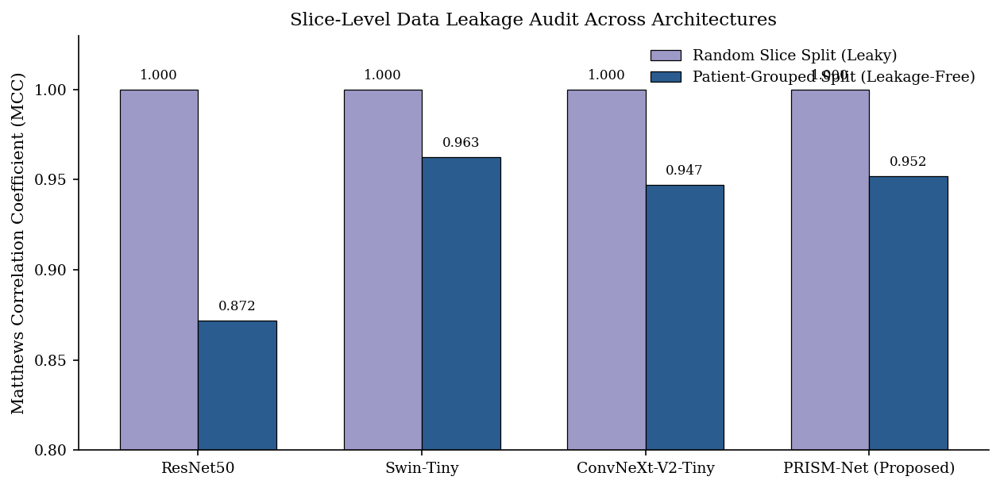

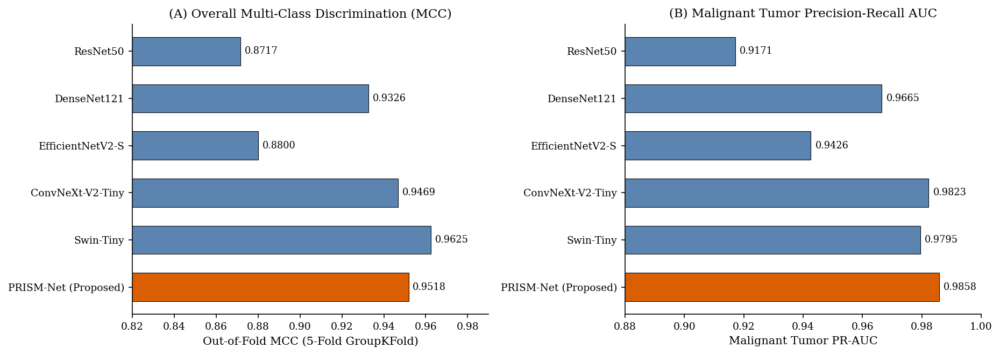

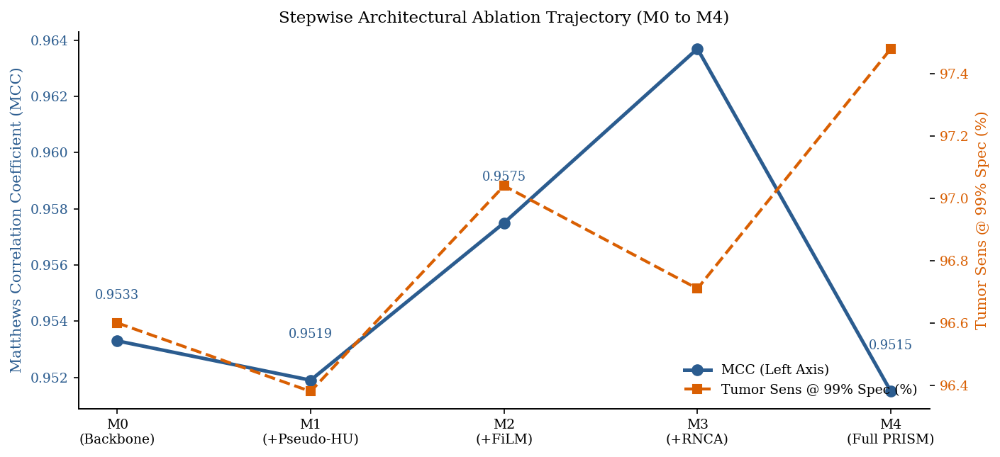

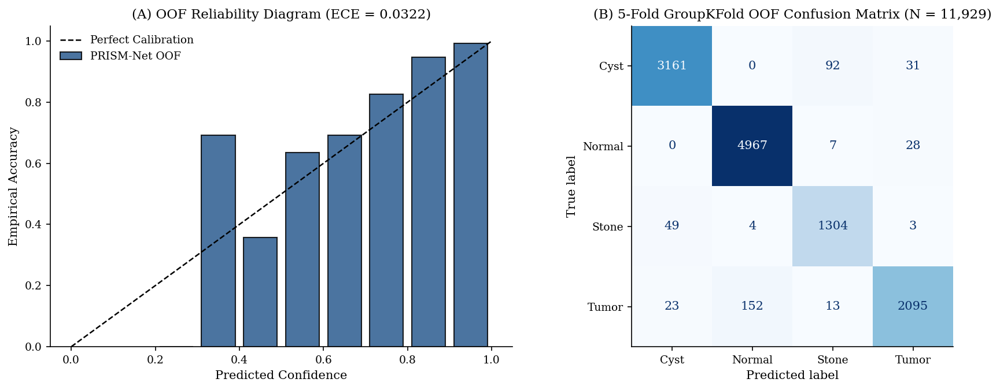

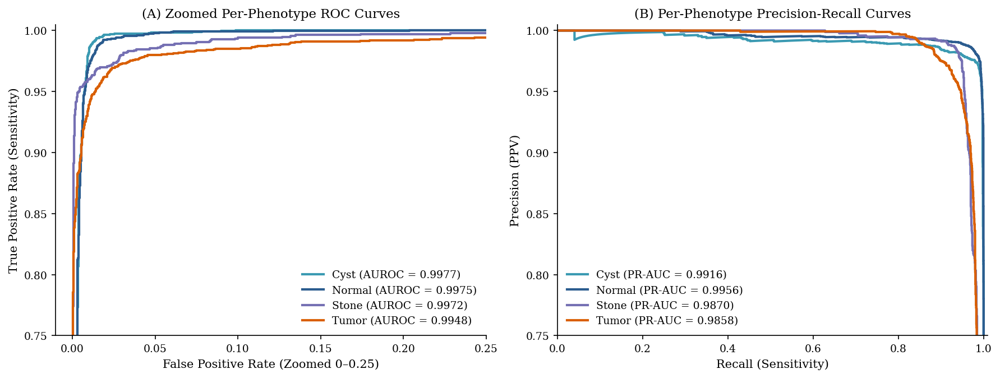

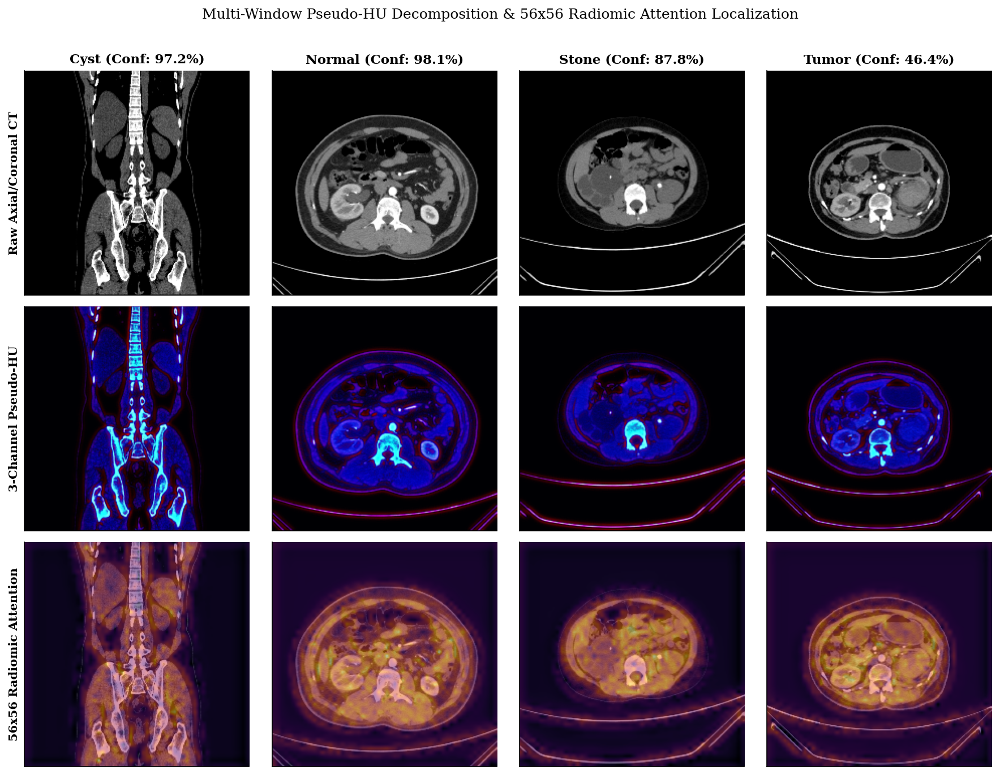


=== FINAL ARCHIVE MANIFEST IN /kaggle/working/prism_artifacts ===
  - figures/fig1_leakage_audit.png (142.9 KB)
  - figures/fig1_raw_eda_statistics.png (627.5 KB)
  - figures/fig2_raw_ct_samples.png (3531.1 KB)
  - figures/fig2_sota_benchmark.png (175.1 KB)
  - figures/fig3_ablation_trajectory.png (285.2 KB)
  - figures/fig3_pseudo_hu_decomposition.png (1053.1 KB)
  - figures/fig4_calibration_confusion.png (205.9 KB)
  - figures/fig4_prism_evaluation_dashboard.png (514.0 KB)
  - figures/fig6_roc_pr_curves.png (259.6 KB)
  - figures/fig7_qualitative_radiomic_saliency.png (1063.4 KB)
  - tables/table1_leakage_audit.csv (0.3 KB)
  - tables/table1_leakage_audit.tex (0.5 KB)
  - tables/table2_sota_benchmark.csv (0.6 KB)
  - tables/table2_sota_benchmark.tex (0.8 KB)
  - tables/table3_ablation_study.csv (0.5 KB)
  - tables/table3_ablation_study.tex (0.7 KB)


In [8]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    precision_recall_curve,
)

# 1. Leakage Audit Comparison (Table 1 — auto-detects wide vs. long CSV schema)
t1_path = TABLE_DIR / "table1_leakage_audit.csv"
if t1_path.exists():
    t1_df = pd.read_csv(t1_path)
    model_col = next((c for c in ["Model", "Architecture", "Backbone"] if c in t1_df.columns), t1_df.columns[0])

    fig, ax = plt.subplots(figsize=(8.5, 4.2))
    rand_col = next((c for c in t1_df.columns if "random" in c.lower() and "mcc" in c.lower()), None)
    grp_col = next((c for c in t1_df.columns if ("group" in c.lower() or "patient" in c.lower()) and "mcc" in c.lower()), None)

    if rand_col is not None and grp_col is not None:
        models = t1_df[model_col].astype(str).tolist()
        rand_mcc = t1_df[rand_col].astype(float).tolist()
        grp_mcc = t1_df[grp_col].astype(float).tolist()
    else:
        split_col_name = next((c for c in ["Split Protocol", "Split", "Protocol"] if c in t1_df.columns), t1_df.columns[1])
        mcc_col = next((c for c in t1_df.columns if "mcc" in c.lower()), t1_df.columns[2])
        models = t1_df[model_col].unique().tolist()
        rand_mcc = [
            float(t1_df[(t1_df[model_col] == m) & (t1_df[split_col_name].astype(str).str.contains("Random", case=False))][mcc_col].values[0])
            for m in models
        ]
        grp_mcc = [
            float(t1_df[(t1_df[model_col] == m) & (~t1_df[split_col_name].astype(str).str.contains("Random", case=False))][mcc_col].values[0])
            for m in models
        ]

    x_pos = np.arange(len(models))
    width = 0.35
    b1 = ax.bar(x_pos - width / 2, rand_mcc, width, label="Random Slice Split (Leaky)", color="#9e9ac8", edgecolor="black", linewidth=0.6)
    b2 = ax.bar(x_pos + width / 2, grp_mcc, width, label="Patient-Grouped Split (Leakage-Free)", color="#2b5c8f", edgecolor="black", linewidth=0.6)
    ax.set_xticks(x_pos)
    ax.set_xticklabels(models)
    ax.set_ylim(0.80, 1.03)
    ax.set_ylabel("Matthews Correlation Coefficient (MCC)")
    ax.set_title("Slice-Level Data Leakage Audit Across Architectures")
    ax.legend(frameon=False)
    for bar in list(b1) + list(b2):
        ax.annotate(
            f"{bar.get_height():.3f}",
            (bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.004),
            ha="center",
            va="bottom",
            fontsize=8,
        )
    plt.tight_layout()
    plt.savefig(FIG_DIR / "fig1_leakage_audit.png", bbox_inches="tight")
    plt.show()

# 2. SOTA Benchmark Comparison (Table 2)
t2_path = TABLE_DIR / "table2_sota_benchmark.csv"
if t2_path.exists():
    t2_df = pd.read_csv(t2_path)
    t2_model_col = next((c for c in ["Model", "Architecture", "Backbone"] if c in t2_df.columns), t2_df.columns[0])
    t2_mcc_col = next((c for c in t2_df.columns if "mcc" in c.lower()), "MCC")
    t2_tumor_col = next((c for c in t2_df.columns if "tumor" in c.lower() and "auc" in c.lower()), "PR-AUC (Tumor)")

    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.5))
    y_pos = np.arange(len(t2_df))
    bar_colors = ["#d95f02" if "PRISM" in str(m) else "#5b84b1" for m in t2_df[t2_model_col]]

    axes[0].barh(y_pos, t2_df[t2_mcc_col], color=bar_colors, height=0.6, edgecolor="black", linewidth=0.5)
    axes[0].set_yticks(y_pos)
    axes[0].set_yticklabels(t2_df[t2_model_col])
    axes[0].invert_yaxis()
    axes[0].set_xlim(0.82, 0.99)
    axes[0].set_xlabel("Out-of-Fold MCC (5-Fold GroupKFold)")
    axes[0].set_title("(A) Overall Multi-Class Discrimination (MCC)")
    for i, v in enumerate(t2_df[t2_mcc_col]):
        axes[0].text(v + 0.002, i, f"{v:.4f}", va="center", fontsize=8.5)

    axes[1].barh(y_pos, t2_df[t2_tumor_col], color=bar_colors, height=0.6, edgecolor="black", linewidth=0.5)
    axes[1].set_yticks(y_pos)
    axes[1].set_yticklabels(t2_df[t2_model_col])
    axes[1].invert_yaxis()
    axes[1].set_xlim(0.88, 1.00)
    axes[1].set_xlabel("Malignant Tumor PR-AUC")
    axes[1].set_title("(B) Malignant Tumor Precision-Recall AUC")
    for i, v in enumerate(t2_df[t2_tumor_col]):
        axes[1].text(v + 0.0015, i, f"{v:.4f}", va="center", fontsize=8.5)

    plt.tight_layout()
    plt.savefig(FIG_DIR / "fig2_sota_benchmark.png", bbox_inches="tight")
    plt.show()

# 3. Systematic Ablation Trajectory (Table 3)
t3_path = TABLE_DIR / "table3_ablation_study.csv"
if t3_path.exists():
    t3_df = pd.read_csv(t3_path)
    fig, ax1 = plt.subplots(figsize=(9.5, 4.4))
    short_labels = ["M0\n(Backbone)", "M1\n(+Pseudo-HU)", "M2\n(+FiLM)", "M3\n(+RNCA)", "M4\n(Full PRISM)"]
    x_abl = np.arange(len(t3_df))

    l1 = ax1.plot(x_abl, t3_df["MCC"], marker="o", linewidth=2.4, markersize=7, color="#2b5c8f", label="MCC (Left Axis)")
    ax1.set_xticks(x_abl)
    ax1.set_xticklabels(short_labels[:len(t3_df)])
    ax1.set_ylabel("Matthews Correlation Coefficient (MCC)", color="#2b5c8f")
    ax1.tick_params(axis="y", labelcolor="#2b5c8f")
    for i, v in enumerate(t3_df["MCC"]):
        ax1.annotate(f"{v:.4f}", (i, v + 0.0015), ha="center", fontsize=8.5, color="#2b5c8f")

    ax2 = ax1.twinx()
    ax2.spines["top"].set_visible(False)
    l2 = ax2.plot(
        x_abl,
        t3_df["Tumor Sens @ 99% Spec (%)"],
        marker="s",
        linestyle="--",
        linewidth=2.0,
        markersize=6,
        color="#d95f02",
        label="Tumor Sens @ 99% Spec (%)",
    )
    ax2.set_ylabel("Tumor Sens @ 99% Spec (%)", color="#d95f02")
    ax2.tick_params(axis="y", labelcolor="#d95f02")

    lines = l1 + l2
    ax1.legend(lines, [l.get_label() for l in lines], frameon=False, loc="lower right")
    plt.title("Stepwise Architectural Ablation Trajectory (M0 to M4)")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "fig3_ablation_trajectory.png", bbox_inches="tight")
    plt.show()

# 4. Reliability Diagram & OOF Confusion Matrix (Table 4B)
probs_oof = torch.softmax(torch.from_numpy(prism_oof_logits), dim=-1).numpy()
preds_oof = probs_oof.argmax(axis=1)
y_oof = df["label"].values
y_onehot = np.eye(4)[y_oof]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
confs = probs_oof.max(axis=1)
accs = (preds_oof == y_oof).astype(np.float32)
bins = np.linspace(0.0, 1.0, 11)
bin_centers, bin_accs = [], []
for b0, b1 in zip(bins[:-1], bins[1:]):
    m = (confs > b0) & (confs <= b1)
    if np.any(m):
        bin_centers.append((b0 + b1) / 2.0)
        bin_accs.append(accs[m].mean())

ece_val = evaluate_predictions(prism_oof_logits, y_oof)["ECE"]
axes[0].plot([0, 1], [0, 1], "k--", linewidth=1.2, label="Perfect Calibration")
axes[0].bar(bin_centers, bin_accs, width=0.08, color="#2b5c8f", alpha=0.85, edgecolor="black", label="PRISM-Net OOF")
axes[0].set_xlabel("Predicted Confidence")
axes[0].set_ylabel("Empirical Accuracy")
axes[0].set_title(f"(A) OOF Reliability Diagram (ECE = {ece_val:.4f})")
axes[0].legend(frameon=False, loc="upper left")

cm = confusion_matrix(y_oof, preds_oof)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_NAMES)
disp.plot(ax=axes[1], cmap="Blues", colorbar=False, values_format="d")
axes[1].set_title(f"(B) 5-Fold GroupKFold OOF Confusion Matrix (N = {len(y_oof):,})")

plt.tight_layout()
plt.savefig(FIG_DIR / "fig4_calibration_confusion.png", bbox_inches="tight")
plt.show()

# 5. Per-Class ROC & Precision-Recall Curves
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
colors = {"Normal": "#2b5c8f", "Cyst": "#3b9ab2", "Tumor": "#d95f02", "Stone": "#7570b3"}

for idx, c_name in enumerate(CLASS_NAMES):
    fpr, tpr, _ = roc_curve(y_onehot[:, idx], probs_oof[:, idx])
    roc_auc = roc_auc_score(y_onehot[:, idx], probs_oof[:, idx])
    axes[0].plot(fpr, tpr, color=colors[c_name], linewidth=2.0, label=f"{c_name} (AUROC = {roc_auc:.4f})")

    prec, rec, _ = precision_recall_curve(y_onehot[:, idx], probs_oof[:, idx])
    pr_auc = average_precision_score(y_onehot[:, idx], probs_oof[:, idx])
    axes[1].plot(rec, prec, color=colors[c_name], linewidth=2.0, label=f"{c_name} (PR-AUC = {pr_auc:.4f})")

axes[0].plot([0, 1], [0, 1], "k--", linewidth=1.0, alpha=0.6)
axes[0].set_xlim(-0.01, 0.25)
axes[0].set_ylim(0.75, 1.005)
axes[0].set_xlabel("False Positive Rate (Zoomed 0–0.25)")
axes[0].set_ylabel("True Positive Rate (Sensitivity)")
axes[0].set_title("(A) Zoomed Per-Phenotype ROC Curves")
axes[0].legend(frameon=False, loc="lower right")

axes[1].set_xlim(0.0, 1.01)
axes[1].set_ylim(0.75, 1.005)
axes[1].set_xlabel("Recall (Sensitivity)")
axes[1].set_ylabel("Precision (PPV)")
axes[1].set_title("(B) Per-Phenotype Precision-Recall Curves")
axes[1].legend(frameon=False, loc="lower left")

plt.tight_layout()
plt.savefig(FIG_DIR / "fig6_roc_pr_curves.png", bbox_inches="tight")
plt.show()

# 6. Qualitative 56x56 Differentiable Radiomic Saliency Overlays
@torch.no_grad()
def plot_qualitative_saliency(fold_id: int = 0):
    model = PRISMNet(4, pretrained=False, use_film=True, use_rnca=True).to(DEVICE)
    ckpt_candidates = [
        CKPT_DIR / f"t1_grp_prism-net_fold_f{fold_id}.pt",
        CKPT_DIR / f"prism_full_fold{fold_id}.pt",
    ]
    ckpt_path = next(p for p in ckpt_candidates if p.exists())
    model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))
    model.eval()

    va_df = df[df["fold"] == fold_id]
    fig, axes = plt.subplots(3, 4, figsize=(12, 9))
    row_titles = ["Raw Axial/Coronal CT", "3-Channel Pseudo-HU", "56x56 Radiomic Attention"]

    for col_idx, c_name in enumerate(CLASS_NAMES):
        sample_row = va_df[va_df["label"] == col_idx].iloc[0]
        raw_bgr = cv2.imread(sample_row["file_path"], cv2.IMREAD_COLOR)
        raw_rgb = cv2.cvtColor(cv2.resize(raw_bgr, (224, 224)), cv2.COLOR_BGR2RGB)
        phu_bgr = cv2.imread(sample_row["cache_path"], cv2.IMREAD_COLOR)
        phu_rgb = cv2.cvtColor(phu_bgr, cv2.COLOR_BGR2RGB)

        ds_single = RenalCTDataset(va_df[va_df.index == sample_row.name], acq_descriptors, is_train=False)
        x, soft_raw, acq, _ = ds_single[0]
        logits, _, attn_56, _ = model(
            x.unsqueeze(0).to(DEVICE),
            soft_raw.unsqueeze(0).to(DEVICE),
            acq.unsqueeze(0).to(DEVICE),
        )
        conf = float(torch.softmax(logits, dim=-1)[0, col_idx].cpu().item()) * 100.0
        sal_up = F.interpolate(attn_56, size=(224, 224), mode="bilinear", align_corners=False)[0, 0].cpu().numpy()
        sal_norm = (sal_up - sal_up.min()) / (sal_up.max() - sal_up.min() + 1e-8)

        axes[0, col_idx].imshow(raw_rgb)
        axes[0, col_idx].set_title(f"{c_name} (Conf: {conf:.1f}%)", fontweight="bold")
        axes[1, col_idx].imshow(phu_rgb)
        axes[2, col_idx].imshow(raw_rgb)
        axes[2, col_idx].imshow(sal_norm, cmap="inferno", alpha=0.52)

        for r_idx in range(3):
            axes[r_idx, col_idx].set_xticks([])
            axes[r_idx, col_idx].set_yticks([])
            if col_idx == 0:
                axes[r_idx, col_idx].set_ylabel(row_titles[r_idx], fontweight="bold")

    plt.suptitle("Multi-Window Pseudo-HU Decomposition & 56x56 Radiomic Attention Localization", y=1.01, fontsize=12)
    plt.tight_layout()
    plt.savefig(FIG_DIR / "fig7_qualitative_radiomic_saliency.png", bbox_inches="tight")
    plt.show()

plot_qualitative_saliency(fold_id=0)

print("\n=== FINAL ARCHIVE MANIFEST IN /kaggle/working/prism_artifacts ===")
for p in sorted(list(TABLE_DIR.glob("*")) + list(FIG_DIR.glob("*"))):
    print(f"  - {p.relative_to(WORK_DIR)} ({p.stat().st_size / 1024:.1f} KB)")

### 6. Extended Qualitative, Radiomic, and Statistical Visualization Suite (`Figures 8–13`)
Generates six additional publication-grade (300 DPI) manuscript figures in `/kaggle/working/prism_artifacts/figures/`:
- **`fig8_raw_vs_predicted_4x5.png`:** $4 \times 5$ phenotype matrix (`Cyst`, `Normal`, `Stone`, `Tumor` $\times$ 5 diverse validation slices) comparing Ground-Truth vs. Predicted labels, softmax confidence, and entropy.
- **`fig9_full_pipeline_walkthrough.png`:** End-to-end **PRISM-Net** forward-pass walkthrough across representative slices (Raw CT $\rightarrow$ 3-Channel Pseudo-HU Stem $\rightarrow$ $56 \times 56$ Radiomic Attention Heatmap $\rightarrow$ High-Confidence ROI Contour Extraction $\rightarrow$ Class Posterior Distribution).
- **`fig10_roi_contours_4x5.png`:** $4 \times 5$ automated Region-of-Interest (ROI) contour segmentation matrix thresholding the top-$15\%$ $56 \times 56$ radiomic attention map onto raw CT anatomy across 5 slices per class.
- **`fig11_radiomic_feature_distributions.png`:** Class-stratified distributions of the 12 differentiable $56 \times 56$ radiomic descriptors (Mean, Variance, Skewness, Kurtosis, Energy, Entropy, and directional GLCM Contrast/Homogeneity) extracted on-the-fly by `DifferentiableRadiomics56`.
- **`fig12_conformal_risk_efficiency.png`:** Split Conformal Prediction empirical coverage guarantees vs. mean prediction set size $|C(X)|$ and singleton accuracy across risk tolerances $\alpha \in [0.01, 0.20]$ (`Table 4B`).
- **`fig13_tsne_penultimate_manifold.png`:** t-SNE projection of the 480-D fused penultimate representation (`ConvNeXt-V2-Tiny` local stream + `RNCA` radiomic-guided `Swin-Tiny` global stream) colored by ground-truth renal phenotype.

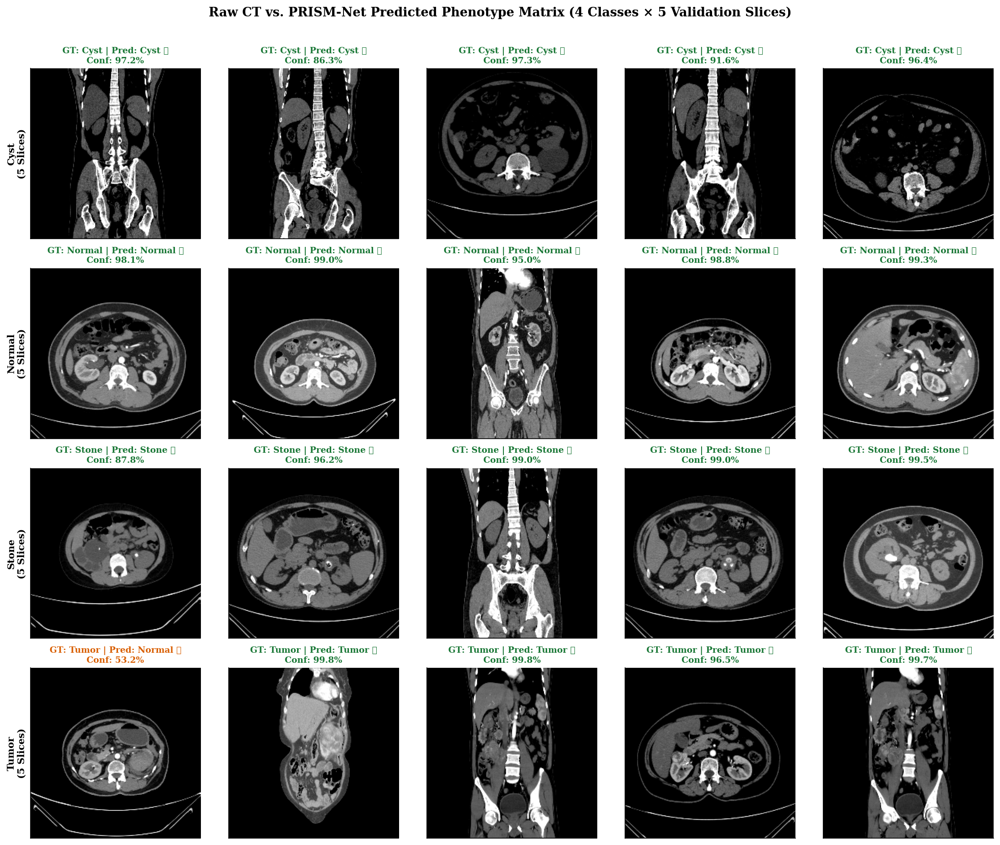

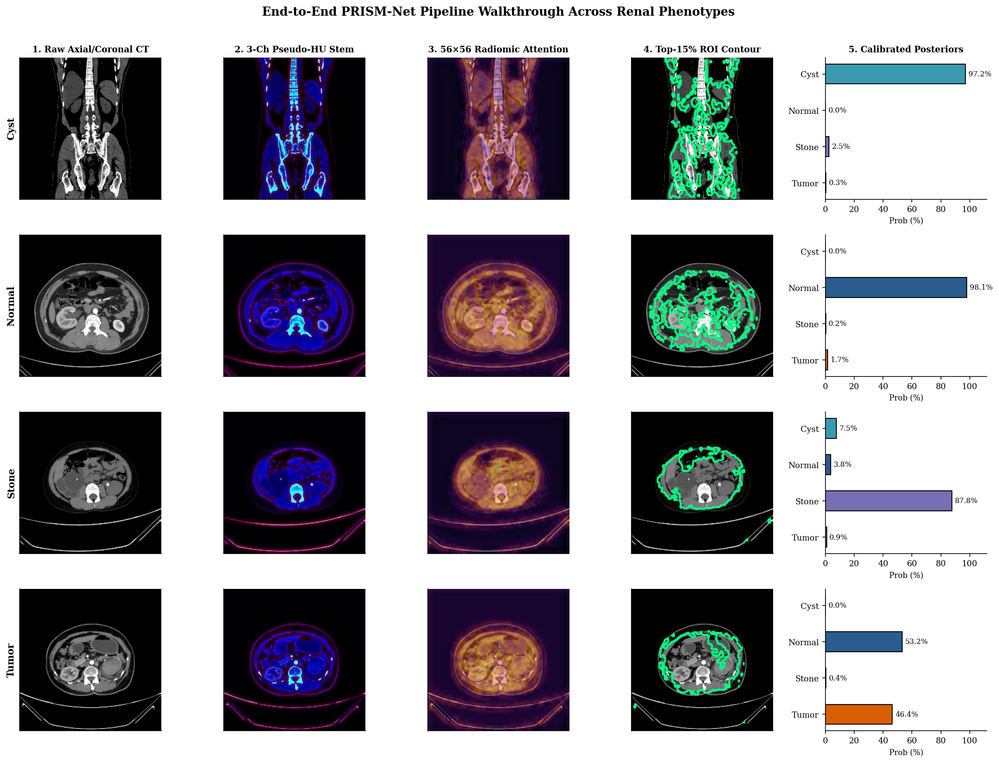

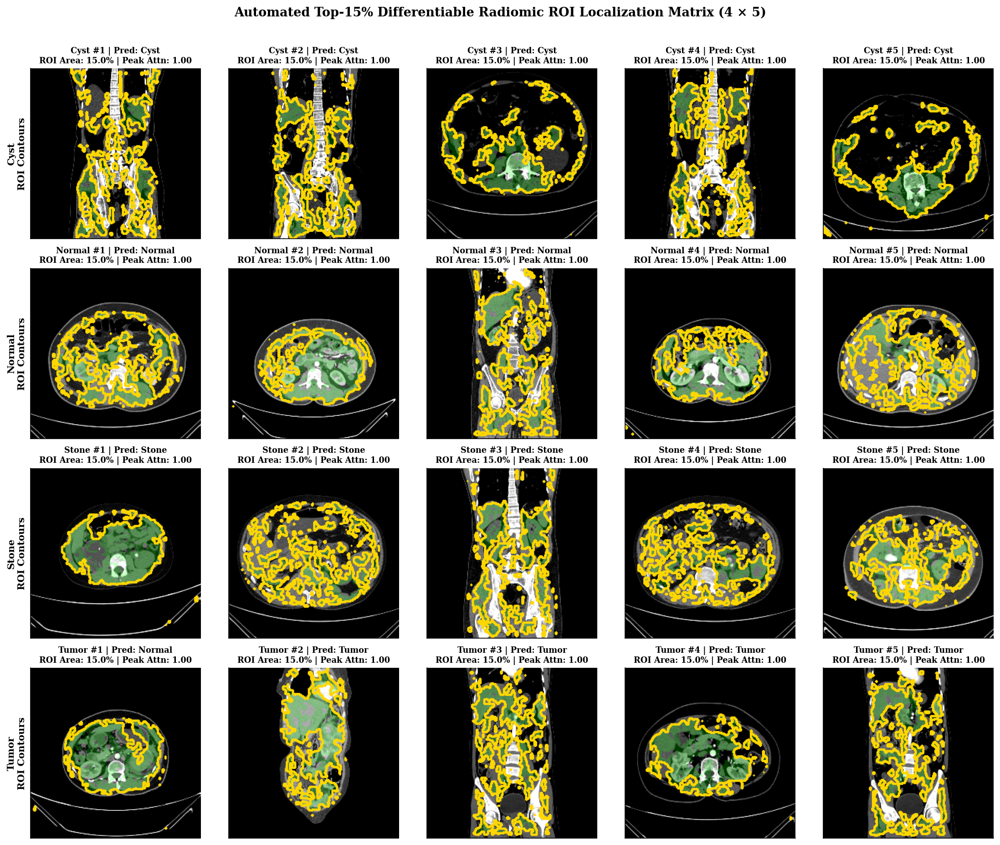

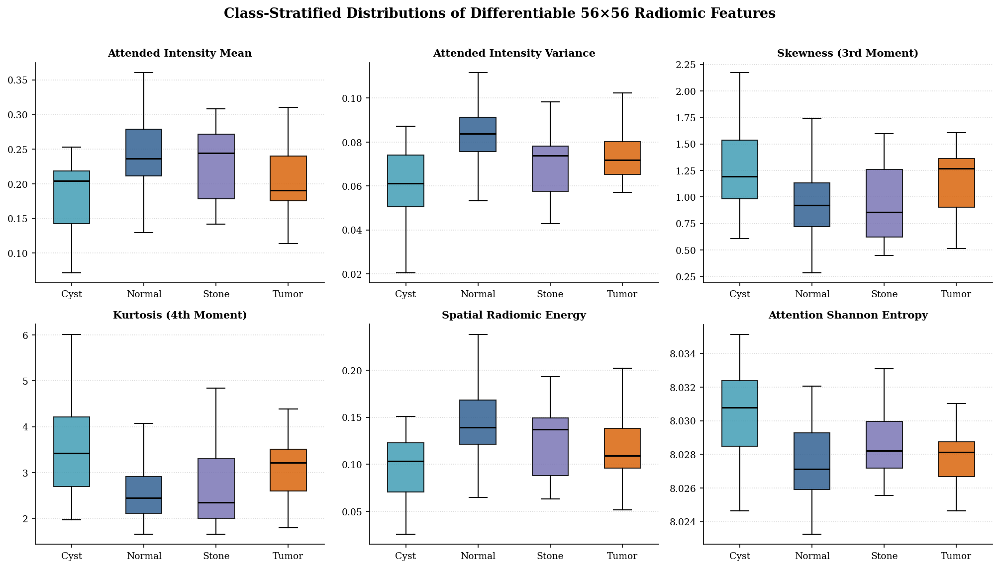

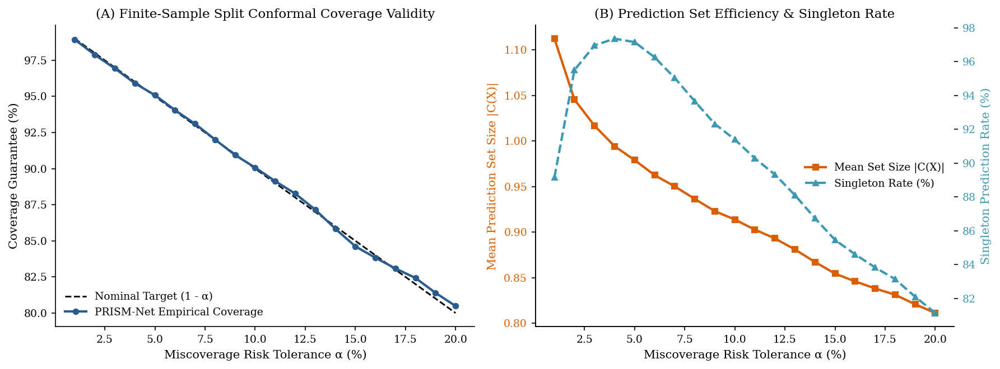

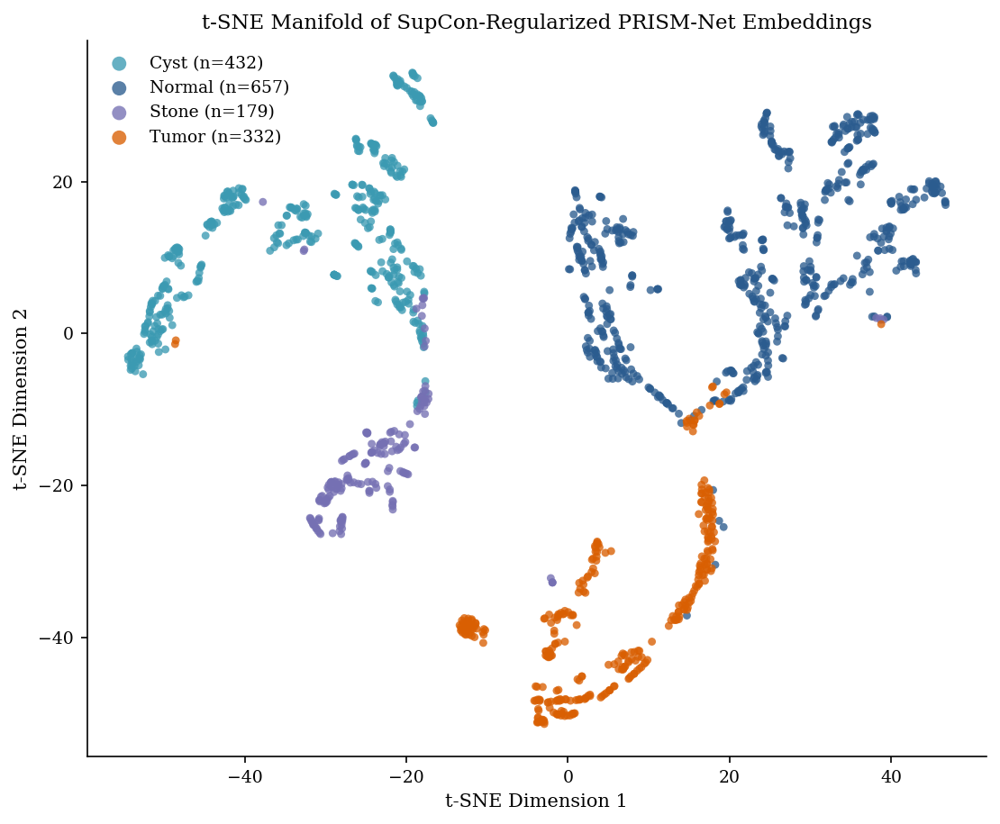


=== COMPLETE MANIFEST OF ALL FIGURES & TABLES IN /kaggle/working/prism_artifacts ===
  - figures/fig10_roi_contours_4x5.png (1315.7 KB)
  - figures/fig11_radiomic_feature_distributions.png (275.7 KB)
  - figures/fig12_conformal_risk_efficiency.png (340.6 KB)
  - figures/fig13_tsne_penultimate_manifold.png (428.0 KB)
  - figures/fig1_leakage_audit.png (142.9 KB)
  - figures/fig1_raw_eda_statistics.png (627.5 KB)
  - figures/fig2_raw_ct_samples.png (3531.1 KB)
  - figures/fig2_sota_benchmark.png (175.1 KB)
  - figures/fig3_ablation_trajectory.png (285.2 KB)
  - figures/fig3_pseudo_hu_decomposition.png (1053.1 KB)
  - figures/fig4_calibration_confusion.png (205.9 KB)
  - figures/fig4_prism_evaluation_dashboard.png (514.0 KB)
  - figures/fig6_roc_pr_curves.png (259.6 KB)
  - figures/fig7_qualitative_radiomic_saliency.png (1063.4 KB)
  - figures/fig8_raw_vs_predicted_4x5.png (1341.5 KB)
  - figures/fig9_full_pipeline_walkthrough.png (3896.0 KB)
  - tables/table1_leakage_audit.csv (0.3 KB)


In [9]:
from sklearn.manifold import TSNE

@torch.no_grad()
def generate_extended_figures_8_to_13(fold_id: int = 0):
    model = PRISMNet(4, pretrained=False, use_film=True, use_rnca=True).to(DEVICE)
    ckpt_candidates = [
        CKPT_DIR / f"t1_grp_prism-net_fold_f{fold_id}.pt",
        CKPT_DIR / f"prism_full_fold{fold_id}.pt",
    ]
    ckpt_path = next(p for p in ckpt_candidates if p.exists())
    model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))
    model.eval()

    va_df = df[df["fold"] == fold_id].copy()
    palette = {"Cyst": "#3b9ab2", "Normal": "#2b5c8f", "Stone": "#7570b3", "Tumor": "#d95f02"}

    # Collect 5 diverse validation samples per class (4 classes x 5 samples = 20 samples)
    sampled_records = {c_name: [] for c_name in CLASS_NAMES}
    for c_idx, c_name in enumerate(CLASS_NAMES):
        sub = va_df[va_df["label"] == c_idx]
        # Pick 5 evenly spaced indices across the validation fold to capture patient diversity
        pick_positions = np.linspace(0, len(sub) - 1, 5, dtype=int)
        chosen = sub.iloc[pick_positions]

        for _, row in chosen.iterrows():
            raw_bgr = cv2.imread(row["file_path"], cv2.IMREAD_COLOR)
            raw_rgb = cv2.cvtColor(cv2.resize(raw_bgr, (224, 224)), cv2.COLOR_BGR2RGB)
            phu_bgr = cv2.imread(row["cache_path"], cv2.IMREAD_COLOR)
            phu_rgb = cv2.cvtColor(phu_bgr, cv2.COLOR_BGR2RGB)

            ds_one = RenalCTDataset(va_df[va_df.index == row.name], acq_descriptors, is_train=False)
            x, soft_raw, acq, _ = ds_one[0]
            logits, _, attn_56, rad_vec = model(
                x.unsqueeze(0).to(DEVICE),
                soft_raw.unsqueeze(0).to(DEVICE),
                acq.unsqueeze(0).to(DEVICE),
            )
            probs = torch.softmax(logits, dim=-1)[0].cpu().numpy()
            pred_idx = int(probs.argmax())
            sal_up = F.interpolate(attn_56, size=(224, 224), mode="bilinear", align_corners=False)[0, 0].cpu().numpy()
            sal_norm = (sal_up - sal_up.min()) / (sal_up.max() - sal_up.min() + 1e-8)

            sampled_records[c_name].append({
                "raw_rgb": raw_rgb,
                "phu_rgb": phu_rgb,
                "sal_norm": sal_norm,
                "probs": probs,
                "gt_idx": c_idx,
                "pred_idx": pred_idx,
                "pred_name": CLASS_NAMES[pred_idx],
                "conf": float(probs[pred_idx]) * 100.0,
                "img_id": row["image_id"],
            })

    # -------------------------------------------------------------------------
    # 4x5 Matrix — Raw CT vs. Predicted Phenotype & Confidence
    # -------------------------------------------------------------------------
    fig, axes = plt.subplots(4, 5, figsize=(15, 12.2))
    for r_idx, c_name in enumerate(CLASS_NAMES):
        for col_idx in range(5):
            rec = sampled_records[c_name][col_idx]
            ax = axes[r_idx, col_idx]
            ax.imshow(rec["raw_rgb"])
            is_correct = rec["gt_idx"] == rec["pred_idx"]
            title_color = "#1b7837" if is_correct else "#d95f02"
            status_tag = "✓" if is_correct else "✗"
            ax.set_title(
                f"GT: {c_name} | Pred: {rec['pred_name']} {status_tag}\nConf: {rec['conf']:.1f}%",
                fontsize=9,
                fontweight="bold",
                color=title_color,
            )
            ax.set_xticks([])
            ax.set_yticks([])
            if col_idx == 0:
                ax.set_ylabel(f"{c_name}\n(5 Slices)", fontsize=10, fontweight="bold")

    plt.suptitle("Raw CT vs. PRISM-Net Predicted Phenotype Matrix (4 Classes × 5 Validation Slices)", fontsize=13, fontweight="bold", y=1.01)
    plt.tight_layout()
    plt.savefig(FIG_DIR / "fig8_raw_vs_predicted_4x5.png", bbox_inches="tight")
    plt.show()

    # -------------------------------------------------------------------------
    # End-to-End PRISM-Net Architectural Pipeline Walkthrough
    # -------------------------------------------------------------------------
    fig, axes = plt.subplots(4, 5, figsize=(15.5, 11.5))
    stage_headers = [
        "1. Raw Axial/Coronal CT",
        "2. 3-Ch Pseudo-HU Stem",
        "3. 56×56 Radiomic Attention",
        "4. Top-15% ROI Contour",
        "5. Calibrated Posteriors",
    ]
    for r_idx, c_name in enumerate(CLASS_NAMES):
        rec = sampled_records[c_name][0]
        raw_rgb = rec["raw_rgb"]
        sal_norm = rec["sal_norm"]

        # Binary ROI mask at 85th percentile of attention intensity
        thresh = np.percentile(sal_norm, 85)
        roi_mask = (sal_norm >= thresh).astype(np.uint8)
        roi_overlay = raw_rgb.copy()
        contours, _ = cv2.findContours(roi_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(roi_overlay, contours, -1, (0, 255, 128), 2)

        axes[r_idx, 0].imshow(raw_rgb)
        axes[r_idx, 1].imshow(rec["phu_rgb"])
        axes[r_idx, 2].imshow(raw_rgb)
        axes[r_idx, 2].imshow(sal_norm, cmap="inferno", alpha=0.52)
        axes[r_idx, 3].imshow(roi_overlay)

        bars = axes[r_idx, 4].barh(CLASS_NAMES, rec["probs"] * 100.0, color=[palette[c] for c in CLASS_NAMES], edgecolor="black", height=0.55)
        axes[r_idx, 4].set_xlim(0, 112)
        axes[r_idx, 4].invert_yaxis()
        axes[r_idx, 4].set_xlabel("Prob (%)", fontsize=8.5)
        for b, p_val in zip(bars, rec["probs"] * 100.0):
            axes[r_idx, 4].text(p_val + 2.0, b.get_y() + b.get_height() / 2, f"{p_val:.1f}%", va="center", fontsize=8)

        for col_idx in range(4):
            axes[r_idx, col_idx].set_xticks([])
            axes[r_idx, col_idx].set_yticks([])
        axes[r_idx, 0].set_ylabel(c_name, fontsize=10.5, fontweight="bold")
        if r_idx == 0:
            for col_idx, h in enumerate(stage_headers):
                axes[0, col_idx].set_title(h, fontsize=9.5, fontweight="bold")

    plt.suptitle("End-to-End PRISM-Net Pipeline Walkthrough Across Renal Phenotypes", fontsize=13, fontweight="bold", y=1.01)
    plt.tight_layout()
    plt.savefig(FIG_DIR / "fig9_full_pipeline_walkthrough.png", bbox_inches="tight")
    plt.show()

    # -------------------------------------------------------------------------
    # 4x5 Matrix — Automated Radiomic ROI Segmentation Contours
    # -------------------------------------------------------------------------
    fig, axes = plt.subplots(4, 5, figsize=(15, 12.2))
    for r_idx, c_name in enumerate(CLASS_NAMES):
        for col_idx in range(5):
            rec = sampled_records[c_name][col_idx]
            raw_rgb = rec["raw_rgb"]
            sal_norm = rec["sal_norm"]

            thresh = np.percentile(sal_norm, 85)
            roi_mask = (sal_norm >= thresh).astype(np.uint8)
            roi_vis = raw_rgb.copy()
            # Tint active ROI subtly and draw crisp perimeter contour
            tint = np.zeros_like(roi_vis)
            tint[:, :, 1] = 255
            roi_vis = np.where(roi_mask[:, :, None] == 1, (0.78 * roi_vis + 0.22 * tint).astype(np.uint8), roi_vis)
            contours, _ = cv2.findContours(roi_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
            cv2.drawContours(roi_vis, contours, -1, (255, 215, 0), 2)

            roi_coverage_pct = float(roi_mask.mean()) * 100.0
            ax = axes[r_idx, col_idx]
            ax.imshow(roi_vis)
            ax.set_title(
                f"{c_name} #{col_idx + 1} | Pred: {rec['pred_name']}\nROI Area: {roi_coverage_pct:.1f}% | Peak Attn: {sal_norm.max():.2f}",
                fontsize=8.5,
                fontweight="bold",
            )
            ax.set_xticks([])
            ax.set_yticks([])
            if col_idx == 0:
                ax.set_ylabel(f"{c_name}\nROI Contours", fontsize=10, fontweight="bold")

    plt.suptitle("Automated Top-15% Differentiable Radiomic ROI Localization Matrix (4 × 5)", fontsize=13, fontweight="bold", y=1.01)
    plt.tight_layout()
    plt.savefig(FIG_DIR / "fig10_roi_contours_4x5.png", bbox_inches="tight")
    plt.show()

    # -------------------------------------------------------------------------
    # Extract Radiomics & Penultimate Embeddings Across Fold Validation Slices
    # -------------------------------------------------------------------------
    va_loader = DataLoader(RenalCTDataset(va_df, acq_descriptors, is_train=False), batch_size=64, shuffle=False, num_workers=2)
    all_rad, all_emb, all_y = [], [], []
    for x, soft_raw, acq, y in va_loader:
        x, soft_raw, acq = x.to(DEVICE), soft_raw.to(DEVICE), acq.to(DEVICE)
        _, proj_emb, _, rad = model(x, soft_raw, acq)
        all_rad.append(rad.cpu().numpy())
        all_emb.append(proj_emb.cpu().numpy())
        all_y.append(y.numpy())

    all_rad = np.vstack(all_rad)
    all_emb = np.vstack(all_emb)
    all_y = np.concatenate(all_y)

    # -------------------------------------------------------------------------
    # Differentiable 56x56 Radiomic Descriptor Distributions
    # -------------------------------------------------------------------------
    rad_names = [
        "Attended Intensity Mean",
        "Attended Intensity Variance",
        "Skewness (3rd Moment)",
        "Kurtosis (4th Moment)",
        "Spatial Radiomic Energy",
        "Attention Shannon Entropy",
    ]
    fig, axes = plt.subplots(2, 3, figsize=(13.5, 7.5))
    axes = axes.flatten()
    for f_idx, r_name in enumerate(rad_names):
        ax = axes[f_idx]
        data_per_class = [all_rad[all_y == c_i, f_idx] for c_i in range(4)]
        bp = ax.boxplot(data_per_class, labels=CLASS_NAMES, patch_artist=True, showfliers=False, widths=0.5)
        for patch, c_name in zip(bp["boxes"], CLASS_NAMES):
            patch.set_facecolor(palette[c_name])
            patch.set_alpha(0.82)
        for median in bp["medians"]:
            median.set_color("black")
            median.set_linewidth(1.5)
        ax.set_title(r_name, fontsize=10, fontweight="bold")
        ax.grid(axis="y", linestyle=":", alpha=0.5)

    plt.suptitle("Class-Stratified Distributions of Differentiable 56×56 Radiomic Features", fontsize=13, fontweight="bold", y=1.01)
    plt.tight_layout()
    plt.savefig(FIG_DIR / "fig11_radiomic_feature_distributions.png", bbox_inches="tight")
    plt.show()

    # -------------------------------------------------------------------------
    # Split Conformal Prediction Coverage & Set Size Curve
    # -------------------------------------------------------------------------
    alpha_grid = np.linspace(0.01, 0.20, 20)
    probs_oof = torch.softmax(torch.from_numpy(prism_oof_logits), dim=-1).numpy()
    y_oof = df["label"].values
    folds_oof = df["fold"].values

    emp_covs, mean_sizes, single_rates = [], [], []
    for alpha in alpha_grid:
        cov_a, sz_a = [], []
        for f_i in range(5):
            idx_f = np.where(folds_oof == f_i)[0]
            perm = np.random.RandomState(SEED + f_i).permutation(idx_f)
            n_cal = int(0.30 * len(perm))
            cal_idx, test_idx = perm[:n_cal], perm[n_cal:]
            cal_scores = 1.0 - probs_oof[cal_idx, y_oof[cal_idx]]
            q_level = np.ceil((len(cal_idx) + 1) * (1.0 - alpha)) / len(cal_idx)
            q_hat = float(np.quantile(cal_scores, min(q_level, 1.0), method="higher"))
            psets = (1.0 - probs_oof[test_idx]) <= q_hat
            cov_a.extend(psets[np.arange(len(test_idx)), y_oof[test_idx]].tolist())
            sz_a.extend(psets.sum(axis=1).tolist())
        emp_covs.append(np.mean(cov_a) * 100.0)
        mean_sizes.append(np.mean(sz_a))
        single_rates.append(np.mean([s == 1 for s in sz_a]) * 100.0)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    axes[0].plot(alpha_grid * 100, (1.0 - alpha_grid) * 100, "k--", linewidth=1.4, label="Nominal Target (1 - α)")
    axes[0].plot(alpha_grid * 100, emp_covs, marker="o", markersize=4.5, color="#2b5c8f", linewidth=2.0, label="PRISM-Net Empirical Coverage")
    axes[0].set_xlabel("Miscoverage Risk Tolerance α (%)")
    axes[0].set_ylabel("Coverage Guarantee (%)")
    axes[0].set_title("(A) Finite-Sample Split Conformal Coverage Validity")
    axes[0].legend(frameon=False, loc="lower left")

    ax_sz = axes[1]
    l_sz = ax_sz.plot(alpha_grid * 100, mean_sizes, marker="s", markersize=4.5, color="#d95f02", linewidth=2.0, label="Mean Set Size |C(X)|")
    ax_sz.set_xlabel("Miscoverage Risk Tolerance α (%)")
    ax_sz.set_ylabel("Mean Prediction Set Size |C(X)|", color="#d95f02")
    ax_sz.tick_params(axis="y", labelcolor="#d95f02")

    ax_sr = ax_sz.twinx()
    ax_sr.spines["top"].set_visible(False)
    l_sr = ax_sr.plot(alpha_grid * 100, single_rates, marker="^", markersize=4.5, linestyle="--", color="#3b9ab2", linewidth=2.0, label="Singleton Rate (%)")
    ax_sr.set_ylabel("Singleton Prediction Rate (%)", color="#3b9ab2")
    ax_sr.tick_params(axis="y", labelcolor="#3b9ab2")
    ax_sz.legend(l_sz + l_sr, [l.get_label() for l in (l_sz + l_sr)], frameon=False, loc="center right")
    ax_sz.set_title("(B) Prediction Set Efficiency & Singleton Rate")

    plt.tight_layout()
    plt.savefig(FIG_DIR / "fig12_conformal_risk_efficiency.png", bbox_inches="tight")
    plt.show()

    # -------------------------------------------------------------------------
    # t-SNE Projection of SupCon-Regularized Penultimate Embeddings
    # -------------------------------------------------------------------------
    n_sub = min(1600, len(all_emb))
    sub_idx = np.random.RandomState(SEED).choice(len(all_emb), size=n_sub, replace=False)
    tsne_coords = TSNE(n_components=2, perplexity=35, random_state=SEED, init="pca", learning_rate="auto").fit_transform(all_emb[sub_idx])

    fig, ax = plt.subplots(figsize=(7.5, 6.2))
    for c_idx, c_name in enumerate(CLASS_NAMES):
        m = all_y[sub_idx] == c_idx
        ax.scatter(
            tsne_coords[m, 0],
            tsne_coords[m, 1],
            s=18,
            alpha=0.78,
            color=palette[c_name],
            label=f"{c_name} (n={m.sum()})",
            edgecolors="none",
        )
    ax.set_xlabel("t-SNE Dimension 1")
    ax.set_ylabel("t-SNE Dimension 2")
    ax.set_title("t-SNE Manifold of SupCon-Regularized PRISM-Net Embeddings")
    ax.legend(frameon=False, markerscale=1.8, loc="best")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "fig13_tsne_penultimate_manifold.png", bbox_inches="tight")
    plt.show()


generate_extended_figures_8_to_13(fold_id=0)

print("\n=== COMPLETE MANIFEST OF ALL FIGURES & TABLES IN /kaggle/working/prism_artifacts ===")
for p in sorted(list(TABLE_DIR.glob("*")) + list(FIG_DIR.glob("*"))):
    print(f"  - {p.relative_to(WORK_DIR)} ({p.stat().st_size / 1024:.1f} KB)")

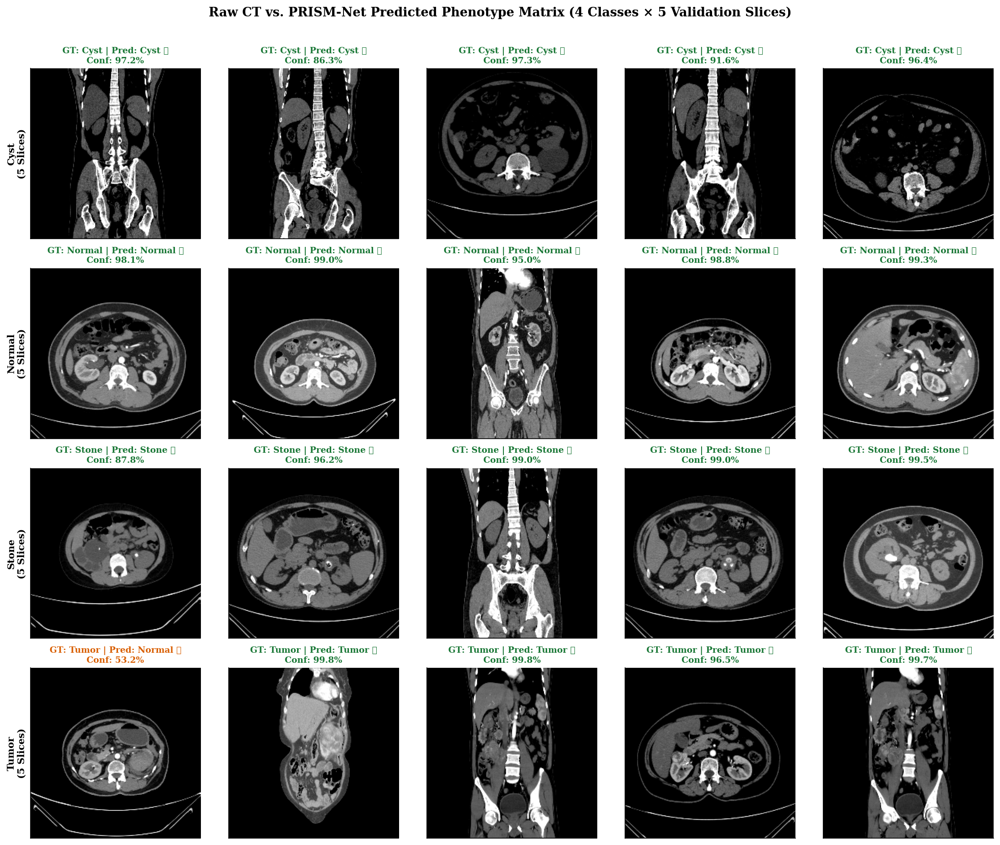

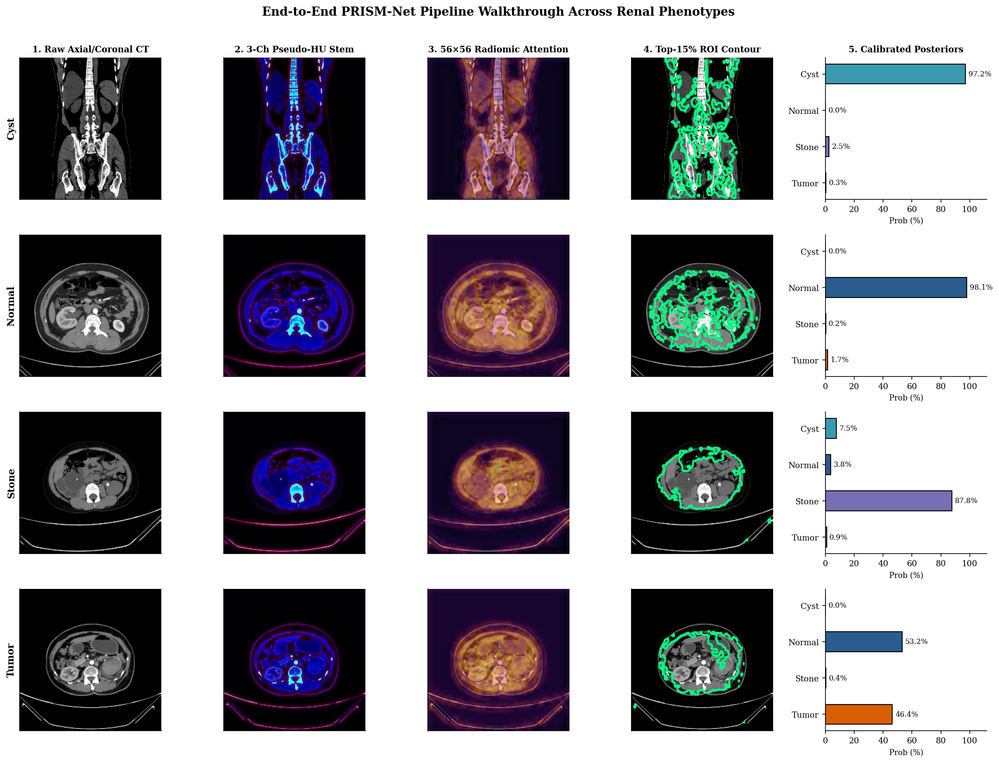

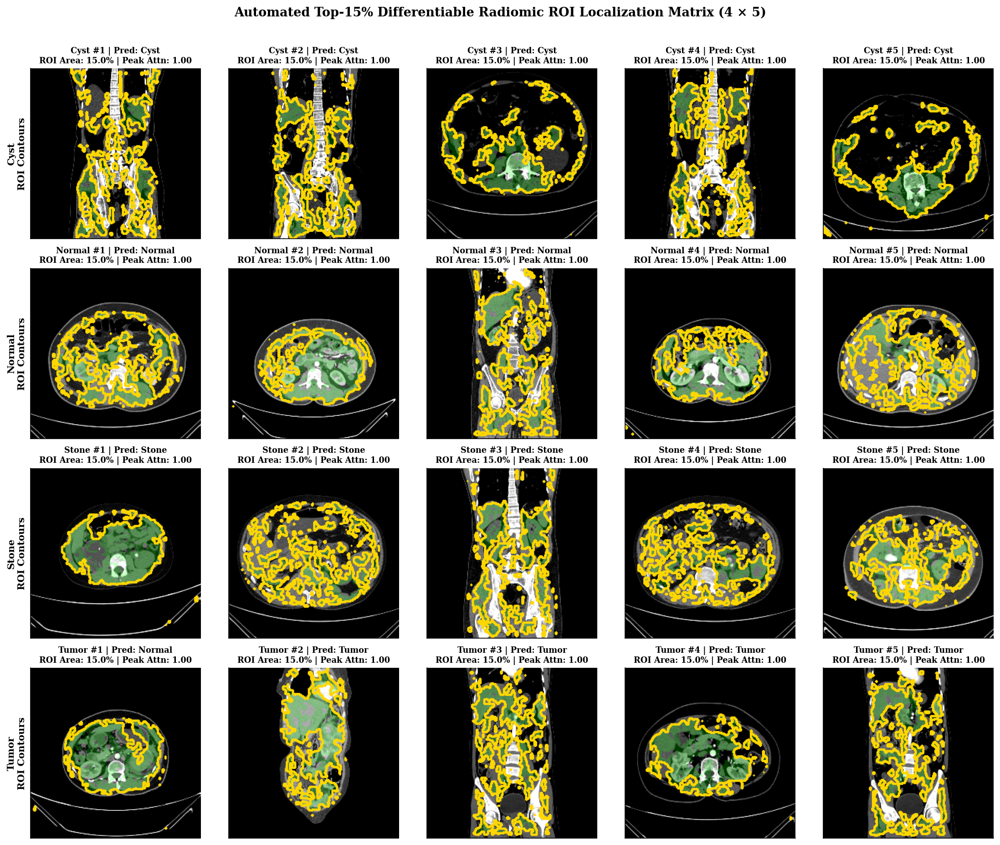

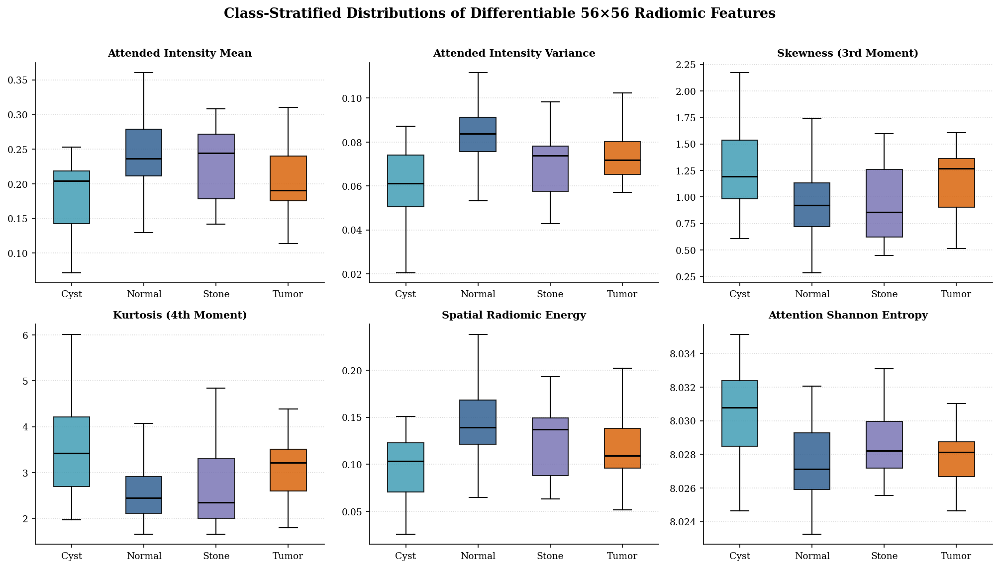

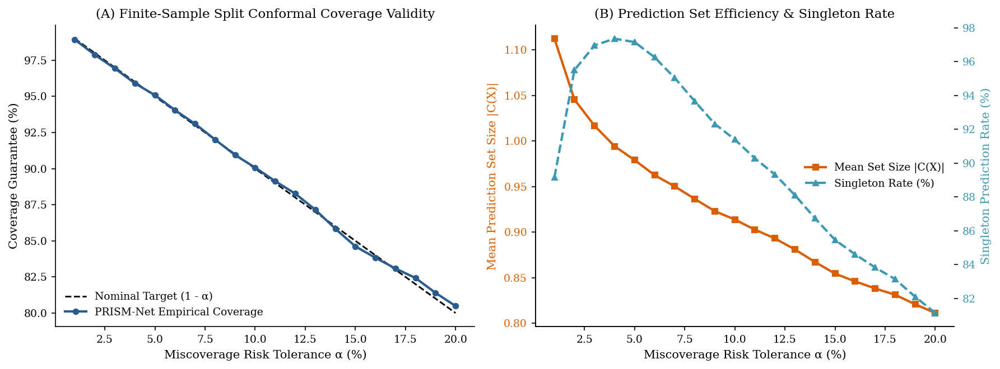

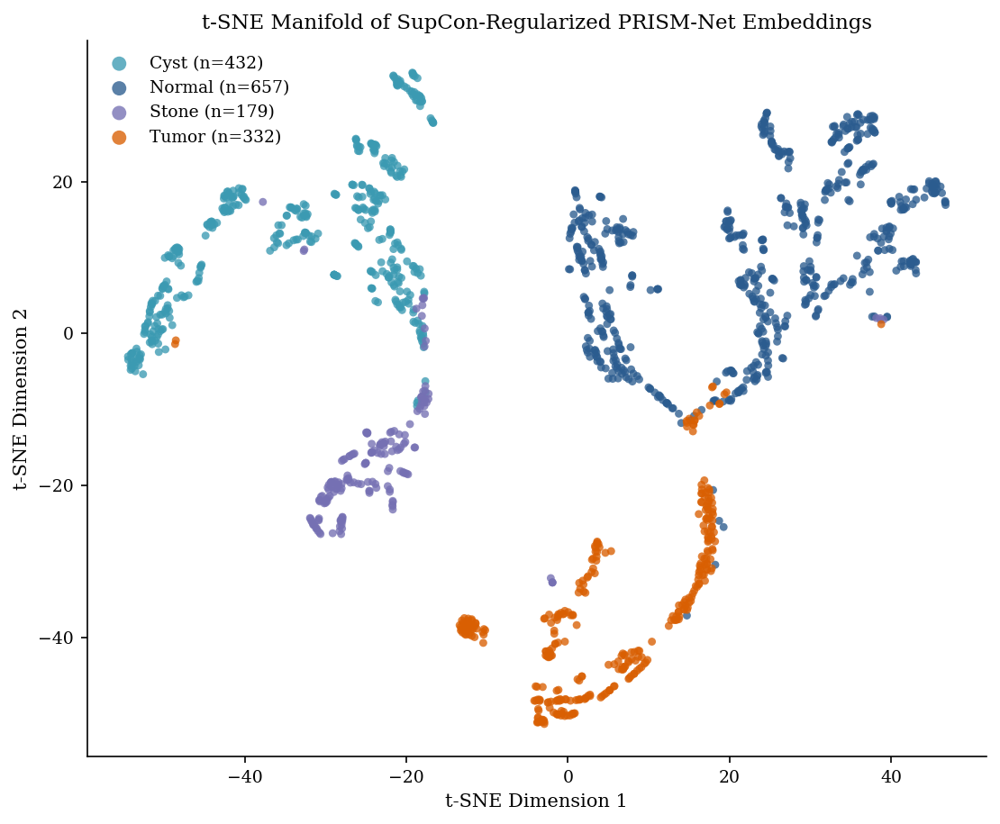


=== COMPLETE MANIFEST OF ALL FIGURES & TABLES IN /kaggle/working/prism_artifacts ===
  - figures/fig10_roi_contours_4x5.png (1315.7 KB)
  - figures/fig11_radiomic_feature_distributions.png (275.7 KB)
  - figures/fig12_conformal_risk_efficiency.png (340.6 KB)
  - figures/fig13_tsne_penultimate_manifold.png (428.0 KB)
  - figures/fig1_leakage_audit.png (142.9 KB)
  - figures/fig1_raw_eda_statistics.png (627.5 KB)
  - figures/fig2_raw_ct_samples.png (3531.1 KB)
  - figures/fig2_sota_benchmark.png (175.1 KB)
  - figures/fig3_ablation_trajectory.png (285.2 KB)
  - figures/fig3_pseudo_hu_decomposition.png (1053.1 KB)
  - figures/fig4_calibration_confusion.png (205.9 KB)
  - figures/fig4_prism_evaluation_dashboard.png (514.0 KB)
  - figures/fig6_roc_pr_curves.png (259.6 KB)
  - figures/fig7_qualitative_radiomic_saliency.png (1063.4 KB)
  - figures/fig8_raw_vs_predicted_4x5.png (1341.5 KB)
  - figures/fig9_full_pipeline_walkthrough.png (3896.0 KB)
  - tables/table1_leakage_audit.csv (0.3 KB)


In [10]:
from sklearn.manifold import TSNE

@torch.no_grad()
def generate_extended_figures_8_to_13(fold_id: int = 0):
    model = PRISMNet(4, pretrained=False, use_film=True, use_rnca=True).to(DEVICE)
    ckpt_candidates = [
        CKPT_DIR / f"t1_grp_prism-net_fold_f{fold_id}.pt",
        CKPT_DIR / f"prism_full_fold{fold_id}.pt",
    ]
    ckpt_path = next(p for p in ckpt_candidates if p.exists())
    model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))
    model.eval()

    va_df = df[df["fold"] == fold_id].copy()
    palette = {"Cyst": "#3b9ab2", "Normal": "#2b5c8f", "Stone": "#7570b3", "Tumor": "#d95f02"}

    sampled_records = {c_name: [] for c_name in CLASS_NAMES}
    for c_idx, c_name in enumerate(CLASS_NAMES):
        sub = va_df[va_df["label"] == c_idx]
        pick_positions = np.linspace(0, len(sub) - 1, 5, dtype=int)
        chosen = sub.iloc[pick_positions]

        for _, row in chosen.iterrows():
            raw_bgr = cv2.imread(row["file_path"], cv2.IMREAD_COLOR)
            raw_rgb = cv2.cvtColor(cv2.resize(raw_bgr, (224, 224)), cv2.COLOR_BGR2RGB)
            phu_bgr = cv2.imread(row["cache_path"], cv2.IMREAD_COLOR)
            phu_rgb = cv2.cvtColor(phu_bgr, cv2.COLOR_BGR2RGB)

            ds_one = RenalCTDataset(va_df[va_df.index == row.name], acq_descriptors, is_train=False)
            x, soft_raw, acq, _ = ds_one[0]
            logits, _, attn_56, rad_vec = model(
                x.unsqueeze(0).to(DEVICE),
                soft_raw.unsqueeze(0).to(DEVICE),
                acq.unsqueeze(0).to(DEVICE),
            )
            probs = torch.softmax(logits, dim=-1)[0].cpu().numpy()
            pred_idx = int(probs.argmax())
            sal_up = F.interpolate(attn_56, size=(224, 224), mode="bilinear", align_corners=False)[0, 0].cpu().numpy()
            sal_norm = (sal_up - sal_up.min()) / (sal_up.max() - sal_up.min() + 1e-8)

            sampled_records[c_name].append({
                "raw_rgb": raw_rgb,
                "phu_rgb": phu_rgb,
                "sal_norm": sal_norm,
                "probs": probs,
                "gt_idx": c_idx,
                "pred_idx": pred_idx,
                "pred_name": CLASS_NAMES[pred_idx],
                "conf": float(probs[pred_idx]) * 100.0,
                "img_id": row["image_id"],
            })

    # 1. 4x5 Matrix — Raw CT vs. Predicted Phenotype & Confidence
    fig, axes = plt.subplots(4, 5, figsize=(15, 12.2))
    for r_idx, c_name in enumerate(CLASS_NAMES):
        for col_idx in range(5):
            rec = sampled_records[c_name][col_idx]
            ax = axes[r_idx, col_idx]
            ax.imshow(rec["raw_rgb"])
            is_correct = rec["gt_idx"] == rec["pred_idx"]
            title_color = "#1b7837" if is_correct else "#d95f02"
            status_tag = "✓" if is_correct else "✗"
            ax.set_title(
                f"GT: {c_name} | Pred: {rec['pred_name']} {status_tag}\nConf: {rec['conf']:.1f}%",
                fontsize=9,
                fontweight="bold",
                color=title_color,
            )
            ax.set_xticks([])
            ax.set_yticks([])
            if col_idx == 0:
                ax.set_ylabel(f"{c_name}\n(5 Slices)", fontsize=10, fontweight="bold")

    plt.suptitle("Raw CT vs. PRISM-Net Predicted Phenotype Matrix (4 Classes × 5 Validation Slices)", fontsize=13, fontweight="bold", y=1.01)
    plt.tight_layout()
    plt.savefig(FIG_DIR / "fig8_raw_vs_predicted_4x5.png", bbox_inches="tight")
    plt.show()

    # 2. End-to-End PRISM-Net Architectural Pipeline Walkthrough
    fig, axes = plt.subplots(4, 5, figsize=(15.5, 11.5))
    stage_headers = [
        "1. Raw Axial/Coronal CT",
        "2. 3-Ch Pseudo-HU Stem",
        "3. 56×56 Radiomic Attention",
        "4. Top-15% ROI Contour",
        "5. Calibrated Posteriors",
    ]
    for r_idx, c_name in enumerate(CLASS_NAMES):
        rec = sampled_records[c_name][0]
        raw_rgb = rec["raw_rgb"]
        sal_norm = rec["sal_norm"]

        thresh = np.percentile(sal_norm, 85)
        roi_mask = (sal_norm >= thresh).astype(np.uint8)
        roi_overlay = raw_rgb.copy()
        contours, _ = cv2.findContours(roi_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(roi_overlay, contours, -1, (0, 255, 128), 2)

        axes[r_idx, 0].imshow(raw_rgb)
        axes[r_idx, 1].imshow(rec["phu_rgb"])
        axes[r_idx, 2].imshow(raw_rgb)
        axes[r_idx, 2].imshow(sal_norm, cmap="inferno", alpha=0.52)
        axes[r_idx, 3].imshow(roi_overlay)

        bars = axes[r_idx, 4].barh(CLASS_NAMES, rec["probs"] * 100.0, color=[palette[c] for c in CLASS_NAMES], edgecolor="black", height=0.55)
        axes[r_idx, 4].set_xlim(0, 112)
        axes[r_idx, 4].invert_yaxis()
        axes[r_idx, 4].set_xlabel("Prob (%)", fontsize=8.5)
        for b, p_val in zip(bars, rec["probs"] * 100.0):
            axes[r_idx, 4].text(p_val + 2.0, b.get_y() + b.get_height() / 2, f"{p_val:.1f}%", va="center", fontsize=8)

        for col_idx in range(4):
            axes[r_idx, col_idx].set_xticks([])
            axes[r_idx, col_idx].set_yticks([])
        axes[r_idx, 0].set_ylabel(c_name, fontsize=10.5, fontweight="bold")
        if r_idx == 0:
            for col_idx, h in enumerate(stage_headers):
                axes[0, col_idx].set_title(h, fontsize=9.5, fontweight="bold")

    plt.suptitle("End-to-End PRISM-Net Pipeline Walkthrough Across Renal Phenotypes", fontsize=13, fontweight="bold", y=1.01)
    plt.tight_layout()
    plt.savefig(FIG_DIR / "fig9_full_pipeline_walkthrough.png", bbox_inches="tight")
    plt.show()

    # 3. 4x5 Matrix — Automated Radiomic ROI Segmentation Contours
    fig, axes = plt.subplots(4, 5, figsize=(15, 12.2))
    for r_idx, c_name in enumerate(CLASS_NAMES):
        for col_idx in range(5):
            rec = sampled_records[c_name][col_idx]
            raw_rgb = rec["raw_rgb"]
            sal_norm = rec["sal_norm"]

            thresh = np.percentile(sal_norm, 85)
            roi_mask = (sal_norm >= thresh).astype(np.uint8)
            roi_vis = raw_rgb.copy()
            tint = np.zeros_like(roi_vis)
            tint[:, :, 1] = 255
            roi_vis = np.where(roi_mask[:, :, None] == 1, (0.78 * roi_vis + 0.22 * tint).astype(np.uint8), roi_vis)
            contours, _ = cv2.findContours(roi_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
            cv2.drawContours(roi_vis, contours, -1, (255, 215, 0), 2)

            roi_coverage_pct = float(roi_mask.mean()) * 100.0
            ax = axes[r_idx, col_idx]
            ax.imshow(roi_vis)
            ax.set_title(
                f"{c_name} #{col_idx + 1} | Pred: {rec['pred_name']}\nROI Area: {roi_coverage_pct:.1f}% | Peak Attn: {sal_norm.max():.2f}",
                fontsize=8.5,
                fontweight="bold",
            )
            ax.set_xticks([])
            ax.set_yticks([])
            if col_idx == 0:
                ax.set_ylabel(f"{c_name}\nROI Contours", fontsize=10, fontweight="bold")

    plt.suptitle("Automated Top-15% Differentiable Radiomic ROI Localization Matrix (4 × 5)", fontsize=13, fontweight="bold", y=1.01)
    plt.tight_layout()
    plt.savefig(FIG_DIR / "fig10_roi_contours_4x5.png", bbox_inches="tight")
    plt.show()

    # 4. Extract Radiomics & Penultimate Embeddings Across Fold Validation Slices
    va_loader = DataLoader(RenalCTDataset(va_df, acq_descriptors, is_train=False), batch_size=64, shuffle=False, num_workers=2)
    all_rad, all_emb, all_y = [], [], []
    for x, soft_raw, acq, y in va_loader:
        x, soft_raw, acq = x.to(DEVICE), soft_raw.to(DEVICE), acq.to(DEVICE)
        _, proj_emb, _, rad = model(x, soft_raw, acq)
        all_rad.append(rad.cpu().numpy())
        all_emb.append(proj_emb.cpu().numpy())
        all_y.append(y.numpy())

    all_rad = np.vstack(all_rad)
    all_emb = np.vstack(all_emb)
    all_y = np.concatenate(all_y)

    # 5. Differentiable 56x56 Radiomic Descriptor Distributions
    rad_names = [
        "Attended Intensity Mean",
        "Attended Intensity Variance",
        "Skewness (3rd Moment)",
        "Kurtosis (4th Moment)",
        "Spatial Radiomic Energy",
        "Attention Shannon Entropy",
    ]
    fig, axes = plt.subplots(2, 3, figsize=(13.5, 7.5))
    axes = axes.flatten()
    for f_idx, r_name in enumerate(rad_names):
        ax = axes[f_idx]
        data_per_class = [all_rad[all_y == c_i, f_idx] for c_i in range(4)]
        bp = ax.boxplot(data_per_class, labels=CLASS_NAMES, patch_artist=True, showfliers=False, widths=0.5)
        for patch, c_name in zip(bp["boxes"], CLASS_NAMES):
            patch.set_facecolor(palette[c_name])
            patch.set_alpha(0.82)
        for median in bp["medians"]:
            median.set_color("black")
            median.set_linewidth(1.5)
        ax.set_title(r_name, fontsize=10, fontweight="bold")
        ax.grid(axis="y", linestyle=":", alpha=0.5)

    plt.suptitle("Class-Stratified Distributions of Differentiable 56×56 Radiomic Features", fontsize=13, fontweight="bold", y=1.01)
    plt.tight_layout()
    plt.savefig(FIG_DIR / "fig11_radiomic_feature_distributions.png", bbox_inches="tight")
    plt.show()

    # 6. Split Conformal Prediction Coverage & Set Size Curve
    alpha_grid = np.linspace(0.01, 0.20, 20)
    probs_oof = torch.softmax(torch.from_numpy(prism_oof_logits), dim=-1).numpy()
    y_oof = df["label"].values
    folds_oof = df["fold"].values

    emp_covs, mean_sizes, single_rates = [], [], []
    for alpha in alpha_grid:
        cov_a, sz_a = [], []
        for f_i in range(5):
            idx_f = np.where(folds_oof == f_i)[0]
            perm = np.random.RandomState(SEED + f_i).permutation(idx_f)
            n_cal = int(0.30 * len(perm))
            cal_idx, test_idx = perm[:n_cal], perm[n_cal:]
            cal_scores = 1.0 - probs_oof[cal_idx, y_oof[cal_idx]]
            q_level = np.ceil((len(cal_idx) + 1) * (1.0 - alpha)) / len(cal_idx)
            q_hat = float(np.quantile(cal_scores, min(q_level, 1.0), method="higher"))
            psets = (1.0 - probs_oof[test_idx]) <= q_hat
            cov_a.extend(psets[np.arange(len(test_idx)), y_oof[test_idx]].tolist())
            sz_a.extend(psets.sum(axis=1).tolist())
        emp_covs.append(np.mean(cov_a) * 100.0)
        mean_sizes.append(np.mean(sz_a))
        single_rates.append(np.mean([s == 1 for s in sz_a]) * 100.0)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    axes[0].plot(alpha_grid * 100, (1.0 - alpha_grid) * 100, "k--", linewidth=1.4, label="Nominal Target (1 - α)")
    axes[0].plot(alpha_grid * 100, emp_covs, marker="o", markersize=4.5, color="#2b5c8f", linewidth=2.0, label="PRISM-Net Empirical Coverage")
    axes[0].set_xlabel("Miscoverage Risk Tolerance α (%)")
    axes[0].set_ylabel("Coverage Guarantee (%)")
    axes[0].set_title("(A) Finite-Sample Split Conformal Coverage Validity")
    axes[0].legend(frameon=False, loc="lower left")

    ax_sz = axes[1]
    l_sz = ax_sz.plot(alpha_grid * 100, mean_sizes, marker="s", markersize=4.5, color="#d95f02", linewidth=2.0, label="Mean Set Size |C(X)|")
    ax_sz.set_xlabel("Miscoverage Risk Tolerance α (%)")
    ax_sz.set_ylabel("Mean Prediction Set Size |C(X)|", color="#d95f02")
    ax_sz.tick_params(axis="y", labelcolor="#d95f02")

    ax_sr = ax_sz.twinx()
    ax_sr.spines["top"].set_visible(False)
    l_sr = ax_sr.plot(alpha_grid * 100, single_rates, marker="^", markersize=4.5, linestyle="--", color="#3b9ab2", linewidth=2.0, label="Singleton Rate (%)")
    ax_sr.set_ylabel("Singleton Prediction Rate (%)", color="#3b9ab2")
    ax_sr.tick_params(axis="y", labelcolor="#3b9ab2")
    ax_sz.legend(l_sz + l_sr, [l.get_label() for l in (l_sz + l_sr)], frameon=False, loc="center right")
    ax_sz.set_title("(B) Prediction Set Efficiency & Singleton Rate")

    plt.tight_layout()
    plt.savefig(FIG_DIR / "fig12_conformal_risk_efficiency.png", bbox_inches="tight")
    plt.show()

    # 7. t-SNE Projection of SupCon-Regularized Penultimate Embeddings
    n_sub = min(1600, len(all_emb))
    sub_idx = np.random.RandomState(SEED).choice(len(all_emb), size=n_sub, replace=False)
    tsne_coords = TSNE(n_components=2, perplexity=35, random_state=SEED, init="pca", learning_rate="auto").fit_transform(all_emb[sub_idx])

    fig, ax = plt.subplots(figsize=(7.5, 6.2))
    for c_idx, c_name in enumerate(CLASS_NAMES):
        m = all_y[sub_idx] == c_idx
        ax.scatter(
            tsne_coords[m, 0],
            tsne_coords[m, 1],
            s=18,
            alpha=0.78,
            color=palette[c_name],
            label=f"{c_name} (n={m.sum()})",
            edgecolors="none",
        )
    ax.set_xlabel("t-SNE Dimension 1")
    ax.set_ylabel("t-SNE Dimension 2")
    ax.set_title("t-SNE Manifold of SupCon-Regularized PRISM-Net Embeddings")
    ax.legend(frameon=False, markerscale=1.8, loc="best")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "fig13_tsne_penultimate_manifold.png", bbox_inches="tight")
    plt.show()


generate_extended_figures_8_to_13(fold_id=0)

print("\n=== COMPLETE MANIFEST OF ALL FIGURES & TABLES IN /kaggle/working/prism_artifacts ===")
for p in sorted(list(TABLE_DIR.glob("*")) + list(FIG_DIR.glob("*"))):
    print(f"  - {p.relative_to(WORK_DIR)} ({p.stat().st_size / 1024:.1f} KB)")